# Confidentiality Notice

In accordance with confidentiality agreements and non-disclosure obligations related to this industrial project, the company name, certain internal identifiers, and several organizational references have been intentionally anonymized in this document. All analyses, methods, results, and conclusions presented remain strictly identical to those of the original version.

# Preliminary Supply Chain Study — Site 1

This notebook implements the preliminary study strictly within the scope defined in the project brief. The analysis is restricted to **Site 1** and follows a coherent workflow: data loading, chronological train/test split, ABC and XYZ classification, ABC/XYZ portfolio matrix, seasonality detection, demand forecasting, lead-time analysis, daily-demand conversion, and minimum-stock computation.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
from google.colab import drive
from statsmodels.tsa.stattools import pacf

In [ ]:
#Function to display the diffrent results
from IPython.display import display

def display_random_rows(df, n=8):
    """
    Display n random rows from a DataFrame instead of the first rows.
    """
    if df is None or len(df) == 0:
        print("DataFrame is empty.")
        return

    n = min(n, len(df))
    display(df.sample(n=n, random_state=np.random.randint(0,100000)))

## 1. Data loading and storage strategy

The raw transaction files are first consolidated into a single table. A Parquet version is then created so that subsequent runs can start from a faster and more stable input file.

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
files = glob.glob("/content/drive/MyDrive/Colab Notebooks/dataPR/*.xlsx")

df = pd.concat([pd.read_excel(f) for f in files], ignore_index=True)

### Data storage choice

At this stage, the raw Excel files have been consolidated into a single dataframe.  
Because repeated Excel loading is slow, the dataset is exported to **Parquet**, which is more efficient for iterative work in Python. This does not change the data itself; it only improves the practical workflow for the study.

In [ ]:
df.to_parquet("/content/drive/MyDrive/Colab Notebooks/dataPR/ventes.parquet")

In [ ]:
df = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/dataPR/ventes.parquet")

## 2. Site 1 extraction and chronological train/test split

The preliminary study is intentionally restricted to **Site 1**. The split between training and test data is performed **in chronological order**, at the monthly level, so that the forecasting stage remains fully out-of-sample.

In [ ]:
# --- Site 1 only ---
site1_work = df[df["Numéro d'entrepôt"] == 1].copy()

# Standardise the order date
site1_work["Date de commande"] = pd.to_datetime(site1_work["Date de commande"], errors="coerce")
#site1_work = site1_work.dropna(subset=["Date de commande"]).copy()

# Monthly key used in the whole study
site1_work["OrderMonth"] = site1_work["Date de commande"].dt.to_period("M")
site1_work["OrderMonthStart"] = site1_work["OrderMonth"].dt.to_timestamp()

# Chronological split on months
all_months = np.array(sorted(site1_work["OrderMonth"].astype(str).unique()))
test_horizon = max(3, min(6, len(all_months) // 4)) if len(all_months) >= 8 else max(1, len(all_months) // 5)
split_month = all_months[-test_horizon] if len(all_months) > test_horizon else all_months[-1]

train_site1 = site1_work[site1_work["OrderMonth"].astype(str) < split_month].copy()
test_site1 = site1_work[site1_work["OrderMonth"].astype(str) >= split_month].copy()

split_summary = pd.DataFrame({
    "Subset": ["Train", "Test"],
    "Rows": [len(train_site1), len(test_site1)],
    "Distinct articles": [train_site1["Code article"].nunique(), test_site1["Code article"].nunique()],
    "Start date": [train_site1["Date de commande"].min(), test_site1["Date de commande"].min()],
    "End date": [train_site1["Date de commande"].max(), test_site1["Date de commande"].max()],
})

split_summary

,Subset,Rows,Distinct articles,Start date,End date
0,Train,2429150,15622,2021-09-09,2024-09-30
1,Test,440413,7941,2024-10-01,2025-03-28


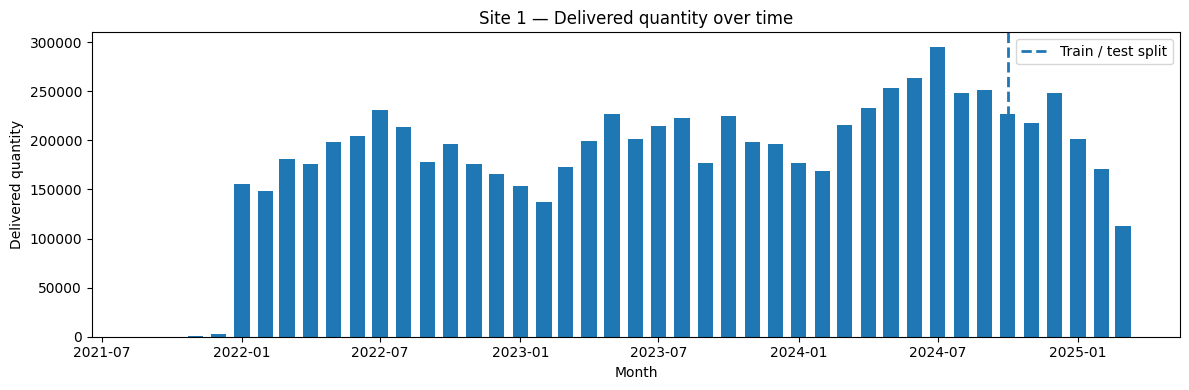

In [ ]:
# Aggregate delivered quantity per month
monthly_demand = (
    site1_work.groupby("OrderMonthStart")["Quantité livrée"]
    .sum()
    .reset_index()
)

split_month_dt = pd.to_datetime(str(split_month))

plt.figure(figsize=(12,4))

plt.bar(
    monthly_demand["OrderMonthStart"],
    monthly_demand["Quantité livrée"],
    width=20
)

plt.axvline(split_month_dt, linestyle="--", linewidth=2, label="Train / test split")

plt.title("Site 1 — Delivered quantity over time")
plt.xlabel("Month")
plt.ylabel("Delivered quantity")

plt.legend()
plt.tight_layout()
plt.show()

## 2. Data quality snapshot

Before going further, a compact data-quality check is useful.  
The goal is not to perform an exhaustive audit of the database, but to document a few elements that directly affect the preliminary study: the size of the sample, the date coverage, missing values, duplicates, and the presence of negative delivered quantities.

These checks help justify later methodological choices, especially for demand aggregation, forecasting, and stock computation.

In [ ]:
quality_snapshot = pd.DataFrame({
    "Metric": [
        "Total rows in Site 1",
        "Distinct articles in Site 1",
        "Missing order dates",
        "Negative delivered quantities",
        "Zero delivered quantities",
        "Min order date",
        "Max order date"
    ],
    "Value": [
        len(site1_work),
        site1_work["Code article"].nunique(),
        site1_work["Date de commande"].isna().sum(),
        (site1_work["Quantité livrée"] < 0).sum(),
        (site1_work["Quantité livrée"] == 0).sum(),
        site1_work["Date de commande"].min(),
        site1_work["Date de commande"].max()
    ]
})

quality_snapshot

,Metric,Value
0,Total rows in Site 1,2869563
1,Distinct articles in Site 1,16631
2,Missing order dates,0
3,Negative delivered quantities,34758
4,Zero delivered quantities,24877
5,Min order date,2021-09-09 00:00:00
6,Max order date,2025-03-28 00:00:00


## 3. ABC classification

The corrected ABC analysis is built on the **training period only**.  
The key correction compared with the initial version is that negative delivered quantities are filtered **before** the article-level aggregation. This ensures that cumulative volume shares are computed on economically meaningful quantities.

The interpretation remains standard: class **A** contains the few items representing the largest share of delivered volume, class **B** corresponds to intermediate contributors, and class **C** groups the long tail of lower-volume articles.

In [ ]:
abc = train_site1.loc[train_site1["Quantité livrée"] >= 0]

abc = (
    abc.groupby("Code article")["Quantité livrée"]
    .sum()
    .reset_index()
)

abc = abc.sort_values("Quantité livrée", ascending=False)

abc["qte_cumulee"] = (
    abc["Quantité livrée"].cumsum()
    / abc["Quantité livrée"].sum()
)

def class_abc(x):
    if x <= 0.8:
        return "A"
    elif x <= 0.95:
        return "B"
    else:
        return "C"

abc["ABC"] = abc["qte_cumulee"].apply(class_abc)

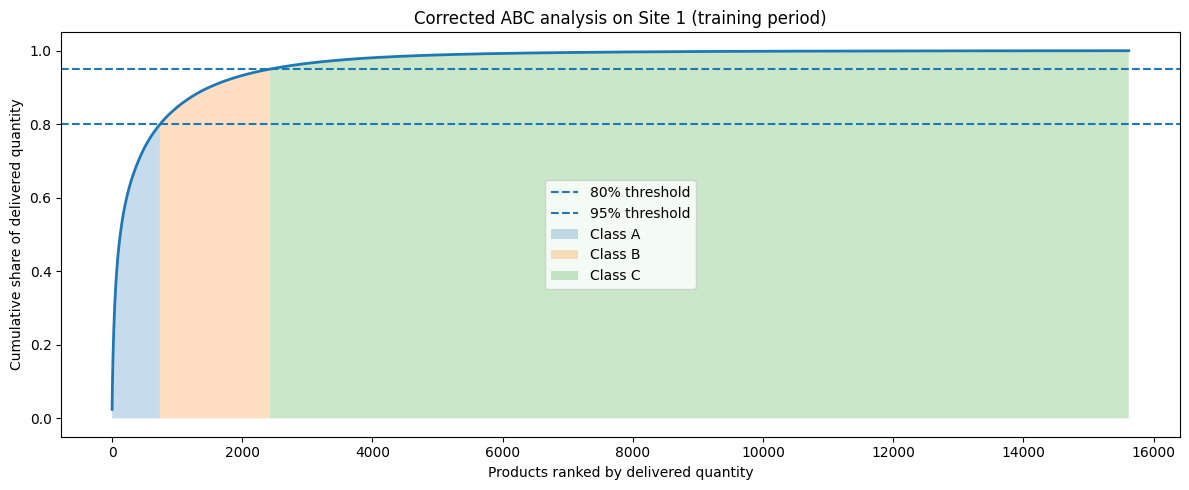

In [ ]:
x = np.arange(len(abc))
y = abc["qte_cumulee"].values

plt.figure(figsize=(12, 5))
plt.plot(x, y, linewidth=2)
plt.axhline(0.80, linestyle="--", label="80% threshold")
plt.axhline(0.95, linestyle="--", label="95% threshold")

plt.fill_between(x, y, where=(y <= 0.80), alpha=0.25, label="Class A")
plt.fill_between(x, y, where=((y > 0.80) & (y <= 0.95)), alpha=0.25, label="Class B")
plt.fill_between(x, y, where=(y > 0.95), alpha=0.25, label="Class C")

plt.title("Corrected ABC analysis on Site 1 (training period)")
plt.xlabel("Products ranked by delivered quantity")
plt.ylabel("Cumulative share of delivered quantity")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Clean monthly demand base for forecasting and XYZ analysis

The next step is to construct a regular **monthly demand base**.  
This table is central to the rest of the study, because it is reused both for the **XYZ classification** and for the **forecasting models**.

To obtain coherent time series, all month/article combinations are completed. Months with no delivery are therefore represented explicitly by zeros. This is important because the absence of demand is itself informative when demand is intermittent or highly variable.

In [ ]:
monthly_train = (
    train_site1.groupby(["Code article", "OrderMonthStart"], as_index=False)["Quantité livrée"]
    .sum()
    .rename(columns={"Quantité livrée": "MonthlyDemand"})
)

month_index_train = pd.date_range(
    monthly_train["OrderMonthStart"].min(),
    monthly_train["OrderMonthStart"].max(),
    freq="MS"
)

articles_train = np.sort(monthly_train["Code article"].unique())

monthly_train_pivot = (
    monthly_train.pivot_table(
        index="OrderMonthStart",
        columns="Code article",
        values="MonthlyDemand",
        aggfunc="sum"
    )
    .reindex(index=month_index_train, columns=articles_train)
    .fillna(0.0)
)

monthly_train_long = (
    monthly_train_pivot.stack()
    .rename("MonthlyDemand")
    .reset_index()
    .rename(columns={"level_0": "Month", "level_1": "Code article"})
)

display_random_rows(monthly_train_pivot)

Code article,0010570,0020342,0025ST,0032734,0032749,0032756,0050164,0050169,0060389,0060430,...,VIG3826O,VSEMIX6,VSEMIX7,YA102,YA302,YA501,YE21134,YRO1243C,YRO1244C,YRO1255C
2024-08-01,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2024-04-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2024-02-01,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,2.0,0.0,0.0,0.0
2023-11-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2022-02-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2024-01-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-03-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2.0,0.0,0.0,3.0,1.0,0.0,0.0
2022-09-01,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


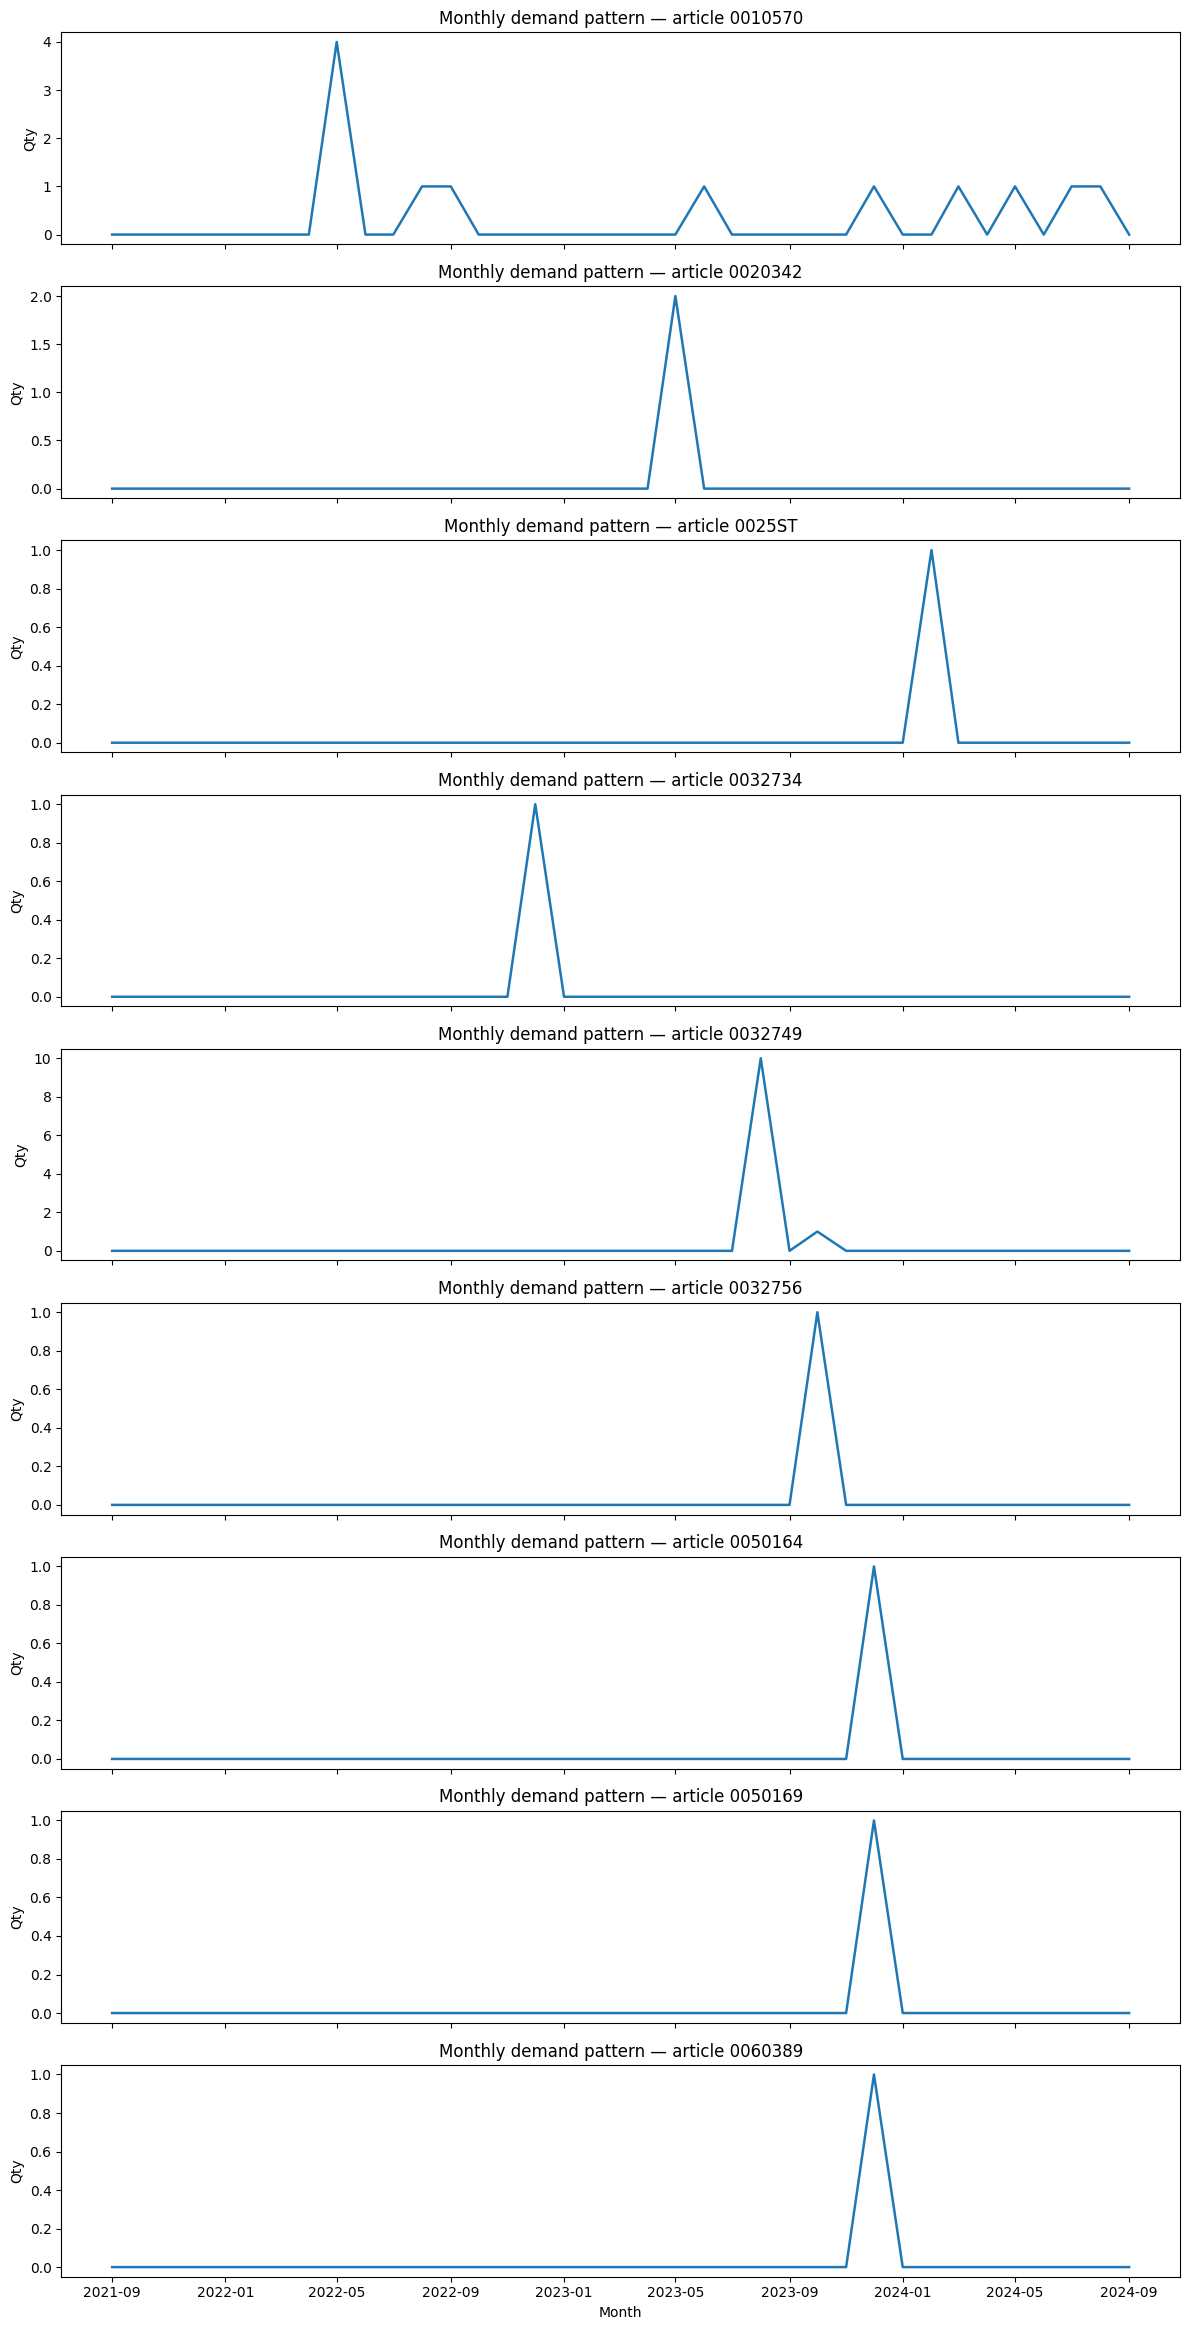

In [ ]:
sample_articles = list(monthly_train_pivot.columns[:min(9, monthly_train_pivot.shape[1])])

if len(sample_articles) > 0:
    fig, axes = plt.subplots(len(sample_articles), 1, figsize=(12, 2.6 * len(sample_articles)), sharex=True)
    if len(sample_articles) == 1:
        axes = [axes]
    for ax, article in zip(axes, sample_articles):
        ax.plot(monthly_train_pivot.index, monthly_train_pivot[article], linewidth=1.8)
        ax.set_title(f"Monthly demand pattern — article {article}")
        ax.set_ylabel("Qty")
    axes[-1].set_xlabel("Month")
    plt.tight_layout()
    plt.show()

## 5. XYZ classification on the monthly demand base

The XYZ classification measures **demand variability**.  
It is based on the coefficient of variation computed from the monthly demand series, which makes it complementary to the ABC classification: ABC reflects the relative importance of items in volume, while XYZ captures the regularity or irregularity of demand over time.

This distinction is useful because two items with similar cumulative volume may imply very different planning and inventory decisions if one has stable demand and the other erratic demand.

In [ ]:
# ============================================================
# XYZ classification corrected (creation + deletion + warehouse=1)
# ============================================================

# Load creation date file
creation = glob.glob("/content/drive/MyDrive/Colab Notebooks/dataPR/dates création/*.xlsx")
creation_df = pd.read_excel(creation[0])

# Keep useful columns (AJOUT entrepôt)
creation_df = creation_df[[
    "Code article",
    "Numéro entrepôt",
    "Date de création de l'article",
    "Date d'annulation de l'article"
]].copy()

# 👉 FILTRE ENTREPÔT = 1
creation_df = creation_df[creation_df["Numéro entrepôt"] == 1].copy()

# Convert dates
creation_df["Date de création de l'article"] = pd.to_datetime(
    creation_df["Date de création de l'article"],
    errors="coerce"
)

creation_df["Date d'annulation de l'article"] = pd.to_datetime(
    creation_df["Date d'annulation de l'article"],
    errors="coerce"
)

# Convert to month start
creation_df["CreationMonth"] = creation_df["Date de création de l'article"].values.astype("datetime64[M]")
creation_df["DeletionMonth"] = creation_df["Date d'annulation de l'article"].values.astype("datetime64[M]")

# ============================================================
# IMPORTANT : gérer les doublons par article
# ============================================================

creation_agg = creation_df.groupby("Code article").agg({
    "CreationMonth": "min",   # earliest creation
    "DeletionMonth": "max"    # latest deletion
}).reset_index()

# Maps propres
creation_map = dict(zip(creation_agg["Code article"], creation_agg["CreationMonth"]))
deletion_map = dict(zip(creation_agg["Code article"], creation_agg["DeletionMonth"]))


# ============================================================
# XYZ computation
# ============================================================

xyz_rows = []

for article in monthly_train_pivot.columns:

    series = monthly_train_pivot[article].copy()

    creation_month = creation_map.get(article, None)
    deletion_month = deletion_map.get(article, None)

    # Filtre période valide
    if creation_month is not None and not pd.isna(creation_month):
        series = series[series.index >= creation_month]

    if deletion_month is not None and not pd.isna(deletion_month):
        series = series[series.index <= deletion_month]

    # Si plus de données
    if len(series) == 0:
        mean_demand = np.nan
        std_demand = np.nan
        cv = np.nan
    else:
        mean_demand = series.mean()
        std_demand = series.std()

        if mean_demand == 0 or pd.isna(mean_demand):
            cv = np.nan
        else:
            cv = std_demand / mean_demand

    xyz_rows.append({
        "Code article": article,
        "MeanMonthlyDemand": mean_demand,
        "StdMonthlyDemand": std_demand,
        "CV": cv
    })


xyz = pd.DataFrame(xyz_rows)


# ============================================================
# XYZ classification
# ============================================================

def classify_xyz(cv):
    if pd.isna(cv):
        return np.nan
    if cv <= 0.10:
        return "X"
    elif cv <= 0.30:
        return "Y"
    else:
        return "Z"


xyz["XYZ"] = xyz["CV"].apply(classify_xyz)

nb_xyz = xyz["XYZ"].value_counts()

print(nb_xyz)
display_random_rows(xyz)

XYZ
Z    14172
Y       66
X       19
Name: count, dtype: int64


,Code article,MeanMonthlyDemand,StdMonthlyDemand,CV,XYZ
11537,4142,22.272727,21.827006,0.979988,Z
10896,38354,0.107143,0.416270,3.885183,Z
13278,5635,3.729730,2.902572,0.778226,Z
10627,34621,7.142857,26.726124,3.741657,Z
3785,2062742,0.210526,0.917663,4.358899,Z
4498,211986,0.027027,0.164399,6.082763,Z
13000,5001124,75.621622,36.188819,0.478551,Z
8942,2535,13.810811,8.161011,0.590915,Z


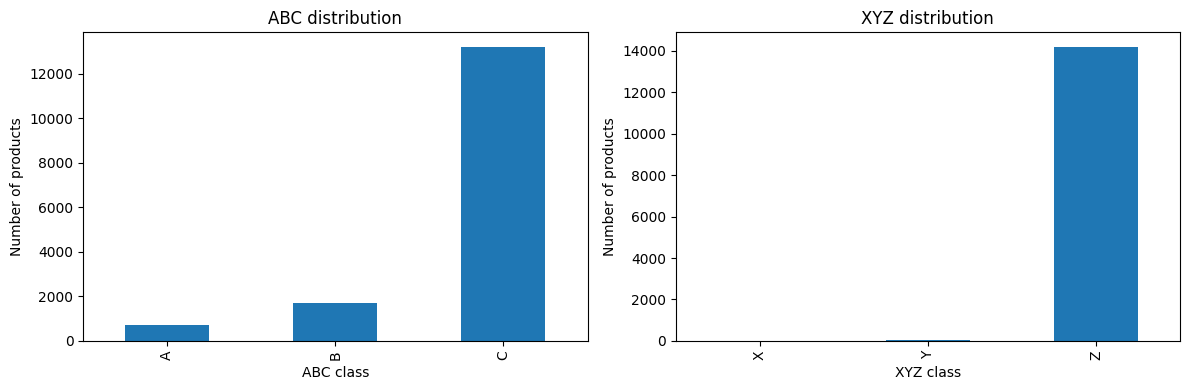

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

abc["ABC"].value_counts().sort_index().plot(kind="bar", ax=axes[0], title="ABC distribution")
axes[0].set_xlabel("ABC class")
axes[0].set_ylabel("Number of products")

xyz["XYZ"].value_counts().sort_index().plot(kind="bar", ax=axes[1], title="XYZ distribution")
axes[1].set_xlabel("XYZ class")
axes[1].set_ylabel("Number of products")

plt.tight_layout()
plt.show()

## 6. ABC/XYZ fusion and matrix visualisation

Once ABC and XYZ are available, they are merged into a joint **ABC/XYZ matrix**.  
This matrix provides a more operational view of the portfolio by combining economic importance and demand variability in a single representation.

The visual matrix is especially useful for communication: it immediately shows where the critical combinations are located, for instance high-volume items with stable demand versus lower-volume items with highly erratic demand.

In [ ]:
abc_xyz = abc[["Code article", "ABC"]].merge(
    xyz[["Code article", "XYZ"]],
    on="Code article",
    how="outer"
)

abc_xyz["ABC_XYZ"] = abc_xyz["ABC"].fillna("?") + abc_xyz["XYZ"].fillna("?")
display_random_rows(abc_xyz)

,Code article,ABC,XYZ,ABC_XYZ
867,171173,C,Z,CZ
14742,DS1990,C,NaN,C?
11884,4339,C,Z,CZ
4853,215135,C,Z,CZ
1576,2002397,C,Z,CZ
5086,218066,C,Z,CZ
12921,5000806,A,Z,AZ
11168,40027029,C,Z,CZ


In [ ]:
abc_xyz_matrix = pd.crosstab(abc_xyz["ABC"], abc_xyz["XYZ"]).reindex(index=["A", "B", "C"], columns=["X", "Y", "Z"])
abc_xyz_matrix

XYZ,X,Y,Z
ABC,,,
A,3,23,683
B,0,27,1600
C,12,16,11889


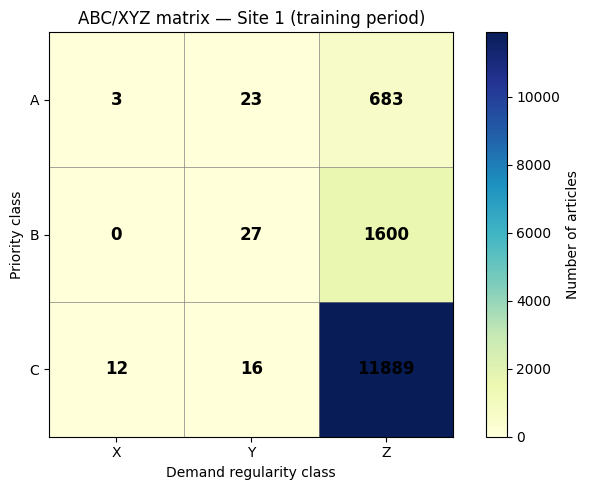

In [ ]:
matrix_values = abc_xyz_matrix.fillna(0).values

fig, ax = plt.subplots(figsize=(7, 5))

# Use a clear colormap (light colors for better readability)
im = ax.imshow(matrix_values, cmap="YlGnBu")

# Axis ticks
ax.set_xticks(np.arange(3))
ax.set_yticks(np.arange(3))
ax.set_xticklabels(["X", "Y", "Z"])
ax.set_yticklabels(["A", "B", "C"])

ax.set_xlabel("Demand regularity class")
ax.set_ylabel("Priority class")
ax.set_title("ABC/XYZ matrix — Site 1 (training period)")

# Add cell values
for i in range(matrix_values.shape[0]):
    for j in range(matrix_values.shape[1]):
        ax.text(
            j, i,
            int(matrix_values[i, j]),
            ha="center",
            va="center",
            color="black",
            fontsize=12,
            fontweight="bold"
        )

# Add colorbar for interpretation
cbar = plt.colorbar(im)
cbar.set_label("Number of articles")

# Add grid lines between cells for readability
ax.set_xticks(np.arange(-.5, 3, 1), minor=True)
ax.set_yticks(np.arange(-.5, 3, 1), minor=True)
ax.grid(which="minor", color="gray", linestyle="-", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()
plt.show()

## 7. Seasonality detection

The seasonal structure of the monthly demand series is investigated through autocorrelation.  
Compared with the first attempt, the method is refined here: instead of keeping the **first** significant lag, we retain the **strongest significant lag** within the first twelve months.

This correction is important because several lags can be significant at the same time, and the first one is not necessarily the most relevant from a forecasting perspective. The selected lag is then used to guide the choice between non-seasonal and seasonal exponential smoothing models.

In [ ]:
candidate_lags = [3, 4, 6, 12]  # ← uniquement les lags métier pertinents
acf_rows = []

for article in monthly_train_pivot.columns:
    series = monthly_train_pivot[article].astype(float)
    n = series.shape[0]
    significance_threshold = 1.96 / np.sqrt(n) if n > 0 else np.nan

    row = {"Code article": article, "SignificanceThreshold": significance_threshold}

    if series.std() == 0 or n < 3:
        for lag in candidate_lags:
            row[f"ACF_{lag}"] = np.nan
        row["SeasonalLag"] = np.nan
        row["MaxSignificantACF"] = np.nan
        acf_rows.append(row)
        continue

    acf_values = {}
    for lag in candidate_lags:
        acf_values[lag] = series.autocorr(lag=lag) if lag < n else np.nan
        row[f"ACF_{lag}"] = acf_values[lag]

    significant_positive_lags = [
        lag for lag, val in acf_values.items()
        if pd.notna(val) and val > significance_threshold and val > 0
    ]

    if len(significant_positive_lags) == 0:
        row["SeasonalLag"] = np.nan
        row["MaxSignificantACF"] = np.nan
    else:
        best_lag = max(significant_positive_lags, key=lambda lag: acf_values[lag])
        row["SeasonalLag"] = best_lag
        row["MaxSignificantACF"] = acf_values[best_lag]

    acf_rows.append(row)

seasonality_df = pd.DataFrame(acf_rows)
seasonality_df[["Code article", "SeasonalLag", "MaxSignificantACF"]].head(10)

Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :

,Code article,SeasonalLag,MaxSignificantACF
0,0010570,NaN,NaN
1,0020342,NaN,NaN
2,0025ST,NaN,NaN
3,0032734,NaN,NaN
4,0032749,NaN,NaN
5,0032756,NaN,NaN
6,0050164,NaN,NaN
7,0050169,NaN,NaN
8,0060389,NaN,NaN
9,0060430,NaN,NaN


In [ ]:
# Tabulate the selected seasonal lags.
# Distribution of detected seasonal lags
seasonality_counts = seasonality_df["SeasonalLag"].value_counts(dropna=False).sort_index()
seasonality_counts

,count
SeasonalLag,
3.0,1474
4.0,445
6.0,315
12.0,1662
NaN,11726


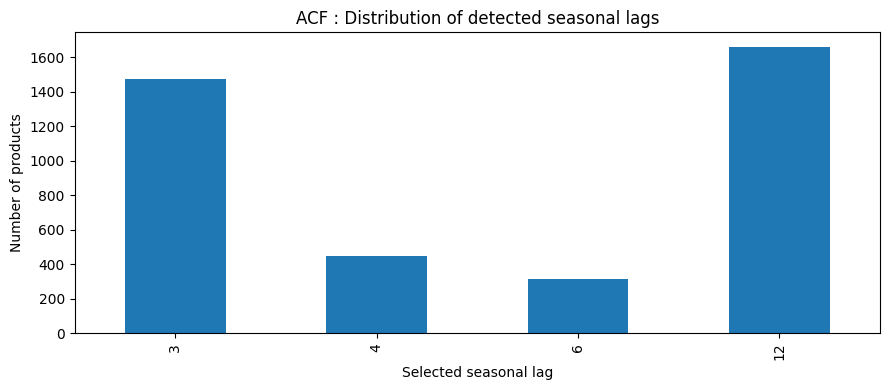

In [ ]:
# Visualise the distribution of the selected seasonal lags.
seasonality_plot = seasonality_df["SeasonalLag"].dropna()

plt.figure(figsize=(9, 4))
if len(seasonality_plot) > 0:
    seasonality_plot.astype(int).value_counts().sort_index().plot(kind="bar")
plt.title("ACF : Distribution of detected seasonal lags")
plt.xlabel("Selected seasonal lag")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()

## 8. Monthly forecasting with exponential smoothing

The forecasting stage follows the logic described in the project brief.  
Depending on the properties of each series, the notebook uses **simple exponential smoothing**, **Holt’s trend model**, or **Holt–Winters exponential smoothing** when a valid seasonal lag is detected.

The purpose here is not to build the most sophisticated predictive system possible, but to produce a coherent and scientifically defensible preliminary benchmark aligned with the study requirements.

In [ ]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Standard exponential smoothing model selection
# ------------------------------------------------------------
def fit_exponential_smoothing(series, seasonal_lag):
    series = pd.Series(series).astype(float)

    if series.std() == 0:
        return None, "constant"

    if pd.notna(seasonal_lag):
        seasonal_lag = int(seasonal_lag)

        if seasonal_lag >= 2 and len(series) >= 2 * seasonal_lag:
            try:
                model = ExponentialSmoothing(
                    series,
                    trend="add",
                    seasonal="add",
                    seasonal_periods=seasonal_lag,
                    initialization_method="estimated"
                ).fit(optimized=True)
                return model, f"HoltWinters({seasonal_lag})"
            except Exception:
                pass

    try:
        model = Holt(
            series,
            damped_trend=True,  # ← correction ici
            initialization_method="estimated"
        ).fit(optimized=True)
        return model, "Holt_damped"

    except Exception:
        model = SimpleExpSmoothing(
            series,
            initialization_method="estimated"
        ).fit(optimized=True)
        return model, "SimpleExpSmoothing"

# ------------------------------------------------------------
# Main forecasting loop — plus de cas spécial AZ
# ------------------------------------------------------------
forecast_records = []

# Define forecast_horizon here, for example based on the test_horizon from earlier analysis
# Assuming test_horizon is available from the previous cells (e.g., cell dd8c4db0)
# If not, a default value like 6 could be used, but using test_horizon is more robust.
# From the kernel state, test_horizon is 6.
forecast_horizon = test_horizon

# Define monthly_test_pivot for forecasting loop
# Need to generate a monthly pivot table for the test set similar to monthly_train_pivot
# Recreate it using the 'test_site1' DataFrame and the 'all_months' variable

# Get the list of all unique article codes from the training set for consistent columns
articles_test = monthly_train_pivot.columns.unique()

# Filter test_site1 to include only articles present in monthly_train_pivot columns
test_site1_filtered = test_site1[test_site1["Code article"].isin(articles_test)]

# Aggregate monthly demand for the test set
monthly_test = (
    test_site1_filtered.groupby(["Code article", "OrderMonthStart"])["Quantité livrée"]
    .sum()
    .reset_index()
    .rename(columns={"Quantité livrée": "MonthlyDemand"})
)

# Get the months for the test set
# Filter all_months to get only the test months
test_months = np.array([m for m in all_months if m >= split_month])

# Convert test_months to datetime objects for reindexing
month_index_test = pd.to_datetime(test_months).to_period("M").to_timestamp()

# Create the monthly_test_pivot table
monthly_test_pivot = (
    monthly_test.pivot_table(
        index="OrderMonthStart",
        columns="Code article",
        values="MonthlyDemand",
        aggfunc="sum"
    )
    .reindex(index=month_index_test, columns=articles_test)
    .fillna(0.0)
)

# Define article_category_map, which is also missing
# Merge abc and xyz to create article_category_map for ABC_XYZ classification
article_category_map = abc_xyz.copy()

if forecast_horizon > 0:

    for article in monthly_train_pivot.columns:

        train_series = monthly_train_pivot[article]

        if article in monthly_test_pivot.columns:
            test_series = monthly_test_pivot[article]
        else:
            test_series = pd.Series(index=monthly_test_pivot.index, data=0.0)

        seasonal_match = seasonality_df.loc[
            seasonality_df["Code article"] == article, "SeasonalLag"
        ]
        seasonal_lag = seasonal_match.iloc[0] if len(seasonal_match) > 0 else np.nan

        category_match = article_category_map.loc[
            article_category_map["Code article"] == article, "ABC_XYZ"
        ]
        article_category = category_match.iloc[0] if len(category_match) > 0 else np.nan

        model, model_name = fit_exponential_smoothing(train_series, seasonal_lag)

        if model is None:
            fallback_value = train_series.iloc[-3:].median()
            pred = pd.Series(
                [fallback_value] * forecast_horizon,
                index=monthly_test_pivot.index
            )
        else:
            pred = pd.Series(
                model.forecast(forecast_horizon),
                index=monthly_test_pivot.index
            )

        pred = pred.clip(lower=0)

        for dt, actual, forecast_value in zip(
            monthly_test_pivot.index,
            test_series.values,
            pred.values
        ):
            forecast_records.append({
                "Code article": article,
                "Month": dt,
                "ActualDemand": float(actual),
                "ForecastDemand": float(forecast_value),
                "ModelUsed": model_name,
                "SeasonalLag": seasonal_lag,
                "ABC_XYZ": article_category
            })

forecast_df1 = pd.DataFrame(forecast_records)

display_random_rows(forecast_df1)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/holtwinters/model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


,Code article,Month,ActualDemand,ForecastDemand,ModelUsed,SeasonalLag,ABC_XYZ
67914,4018,2024-10-01,0.0,0.027608,Holt_damped,NaN,CZ
55174,266415Z,2025-02-01,0.0,0.217787,Holt_damped,NaN,CZ
19905,2062061,2025-01-01,0.0,0.105378,Holt_damped,NaN,CZ
33658,225810,2025-02-01,0.0,0.421159,Holt_damped,NaN,CZ
80501,60191,2025-03-01,4.0,4.949331,Holt_damped,NaN,CZ
65829,39336,2025-01-01,0.0,0.000000,Holt_damped,NaN,CZ
89739,DS3825,2025-01-01,0.0,0.439394,Holt_damped,NaN,CZ
23170,206445,2025-02-01,0.0,0.515232,Holt_damped,NaN,CZ


In [ ]:
# ===============================
# EXPORT EXCEL PAR CATEGORIE - MODELE DE BASE
# ===============================

# Ajouter ABC_XYZ si absent
if "ABC_XYZ" not in forecast_df1.columns:
    print("Ajout de ABC_XYZ dans forecast_df1...")

    forecast_df1 = forecast_df1.merge(
        stock_base[["Code article", "ABC", "XYZ"]],
        on="Code article",
        how="left"
    )

    forecast_df1["ABC_XYZ"] = (
        forecast_df1["ABC"].astype(str)
        + forecast_df1["XYZ"].astype(str)
    )

print("BASE - catégories présentes :")
print(forecast_df1["ABC_XYZ"].value_counts(dropna=False))

import os

output_dir = "/content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast"
os.makedirs(output_dir, exist_ok=True)

abcxyz_order = ["AX", "AY", "AZ", "BX", "BY", "BZ", "CX", "CY", "CZ"]

for cat in abcxyz_order:

    df_cat = forecast_df1[forecast_df1["ABC_XYZ"] == cat].copy()

    if df_cat.empty:
        print(f"Aucune donnée pour {cat}")
        continue

    df_cat = df_cat.sort_values(["Code article", "Month"])

    df_cat = df_cat[
        ["Code article", "Month", "ActualDemand", "ForecastDemand", "SeasonalLag"]  # ← ajout ici
    ]

    file_path = f"{output_dir}/forecast_{cat}.xlsx"
    df_cat.to_excel(file_path, index=False)

    print(f"Fichier exporté : {file_path}")

print("Tous les exports du modèle de base sont terminés 🚀")

BASE - catégories présentes :
ABC_XYZ
CZ    71334
BZ     9600
C?     7668
AZ     4098
B?      360
BY      162
A?      162
AY      138
CY       96
CX       72
?X       24
AX       18
Name: count, dtype: int64
Fichier exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast/forecast_AX.xlsx
Fichier exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast/forecast_AY.xlsx
Fichier exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast/forecast_AZ.xlsx
Aucune donnée pour BX
Fichier exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast/forecast_BY.xlsx
Fichier exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast/forecast_BZ.xlsx
Fichier exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast/forecast_CX.xlsx
Fichier exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast/forecast_CY.xlsx
Fichier exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast/for

## 9. Forecast performance evaluation

A forecasting model has little value without a proper evaluation step.  
For that reason, predictions are compared with the held-out test period through standard out-of-sample indicators such as **MAE** and **RMSE**.

This evaluation serves two purposes: it documents the predictive quality of the preliminary approach, and it provides a basis for discussing possible methodological improvements in later stages of the project.

In [ ]:
# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Compute standard out-of-sample forecast accuracy indicators.
# MAPE is protected against division by zero.

def safe_mape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan

    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


evaluation_rows = []

if len(forecast_df1) > 0:

    for article, grp in forecast_df1.groupby("Code article"):

        y_true = grp["ActualDemand"].values
        y_pred = grp["ForecastDemand"].values

        evaluation_rows.append({
            "Code article": article,

            # Added category information
            "ABC_XYZ": grp["ABC_XYZ"].iloc[0],

            "ModelUsed": grp["ModelUsed"].iloc[0],
            "SeasonalLag": grp["SeasonalLag"].iloc[0],

            # Forecast accuracy metrics
            "MAE": mean_absolute_error(y_true, y_pred),

            # Compute RMSE manually
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),

            "MAPE": safe_mape(y_true, y_pred),

            # Baseline indicator
            "MeanActualDemand": np.mean(y_true)
        })

forecast_eval = pd.DataFrame(evaluation_rows).sort_values("RMSE")

display_random_rows(forecast_eval)

,Code article,ABC_XYZ,ModelUsed,SeasonalLag,MAE,RMSE,MAPE,MeanActualDemand
6155,2301392,CZ,Holt_damped,NaN,0.071221,0.071221,NaN,0.000000
6865,2304103,CZ,Holt_damped,NaN,0.989244,0.990576,NaN,0.000000
7581,2308710,CZ,Holt_damped,NaN,0.200167,0.200167,NaN,0.000000
5482,22258,BZ,Holt_damped,NaN,7.350878,9.096136,27.052513,26.666667
15479,GEB3828C,C?,HoltWinters(6),6.0,0.365078,0.457990,83.334612,0.166667
5740,229062,C?,Holt_damped,NaN,0.333333,0.577350,100.000000,0.333333
5435,2220211,CZ,Holt_damped,NaN,0.057119,0.057131,NaN,0.000000
12178,450,CZ,HoltWinters(3),3.0,1.752497,2.043179,151.349725,1.833333


In [ ]:
forecast_eval[["MAE", "RMSE", "MAPE"]].describe().T if len(forecast_eval) > 0 else pd.DataFrame()

,count,mean,std,min,25%,50%,75%,max
MAE,15622.0,7.968625,55.541909,0.0,0.073610,0.396964,2.272727,2846.058100
RMSE,15622.0,9.334752,62.577475,0.0,0.079271,0.471171,2.811007,3016.133154
MAPE,6841.0,112.171786,214.514915,0.0,51.444696,79.742999,100.000000,7099.614209


## 10. Lead-time analysis

Demand uncertainty is only one side of the inventory problem.  
The second side is the variability of **lead time**, which determines how long the system must cover demand before replenishment is received.


In [ ]:
achats = glob.glob("/content/drive/MyDrive/Colab Notebooks/dataPR/achats/*.xlsx")

achats_df = pd.concat([pd.read_excel(f) for f in achats], ignore_index=True)

In [ ]:
lead_time_stats = (
    achats_df
    .loc[achats_df["Numéro d'entrepôt"] == 1]
    .groupby("Code article")["Délai de livraison calculé (en jours)"]
    .agg(["mean", "std", "count"])
    .reset_index()
    .rename(columns={
        "mean": "mu_l",
        "std": "sigma_l",
        "count": "LeadTimeObs"
    })
)

lead_time_stats["sigma_l"] = lead_time_stats["sigma_l"].fillna(0)

display_random_rows(lead_time_stats)

,Code article,mu_l,sigma_l,LeadTimeObs
5079,21463RU,6.777778,3.153481,9
13601,5000979,4.000000,0.000000,1
406,1221,14.000000,3.464102,3
7307,2303968,8.000000,0.000000,1
9827,259039,30.000000,0.000000,1
9149,2418010,9.500000,4.203173,4
14610,7298,11.846154,4.016666,39
3711,2062455,8.000000,0.000000,1


In [ ]:
daily_demand_test_raw = (
    test_site1
    .groupby(["Code article", "Date de commande"])["Quantité livrée"]
    .sum()
    .reset_index()
    .rename(columns={
        "Date de commande": "Date",
        "Quantité livrée": "DemandJour"
    })
)

daily_rows_test = []

for article, df in daily_demand_test_raw.groupby("Code article"):
    df = df.set_index("Date")
    full_index = pd.bdate_range(df.index.min(), df.index.max())
    df = df.reindex(full_index, fill_value=0)
    df.index.name = "Date"
    df = df.reset_index()
    df["Code article"] = article
    daily_rows_test.append(df)

daily_demand_test_base = pd.concat(daily_rows_test, ignore_index=True)

daily_demand_test_base = daily_demand_test_base.merge(
    abc_xyz[["Code article", "ABC_XYZ"]],
    on="Code article",
    how="left"
)

print(f"Articles : {daily_demand_test_base['Code article'].nunique()}")

Articles : 7920


## 12. Minimum stock formulas F1, F2, and F3

The final quantitative step is to compute the three minimum-stock formulas introduced in the project brief.  
These formulas correspond to increasing levels of sophistication:

- **F1** uses average demand and average lead time only;
- **F2** adds demand uncertainty;
- **F3** adds both demand uncertainty and lead-time uncertainty.

This progression is useful because it makes the impact of uncertainty explicit and allows a clear comparison between deterministic and variability-aware stock calculations.

In [ ]:
from statistics import NormalDist
SERVICE_LEVEL = 0.99
z = round(NormalDist().inv_cdf(SERVICE_LEVEL), 2)
z

2.33

In [ ]:
from statistics import NormalDist
SERVICE_LEVEL = 0.99
z = round(NormalDist().inv_cdf(SERVICE_LEVEL), 2)
z

2.33

In [ ]:
last_month_acf = forecast_df1["Month"].max()
forecast_filtered_acf = forecast_df1[forecast_df1["Month"] < last_month_acf]

daily_demand_stats_acf = (
    forecast_filtered_acf.groupby("Code article")["ForecastDemand"]
    .agg(
        mu_d=lambda x: x.mean() / 22,
        sigma_d=lambda x: x.std() / 22
    )
    .reset_index()
)

stock_base_acf = (
    abc_xyz
    .merge(seasonality_df[["Code article", "SeasonalLag"]], on="Code article", how="left")
    .merge(daily_demand_stats_acf, on="Code article", how="left")
    .merge(lead_time_stats, on="Code article", how="left")
    .merge(forecast_eval[["Code article", "ModelUsed", "MAE", "RMSE", "MAPE"]], on="Code article", how="left")
)

stock_base_acf["mu_l"] = stock_base_acf["mu_l"].fillna(0.0)
stock_base_acf["sigma_l"] = stock_base_acf["sigma_l"].fillna(0.0)
stock_base_acf["sigma_d"] = stock_base_acf["sigma_d"].fillna(0.0)

stock_base_acf["F1"] = stock_base_acf["mu_d"] * stock_base_acf["mu_l"]
stock_base_acf["F2"] = stock_base_acf["mu_d"] * stock_base_acf["mu_l"] + z * stock_base_acf["sigma_d"] * np.sqrt(stock_base_acf["sigma_l"])
stock_base_acf["F3"] = stock_base_acf["mu_d"] * stock_base_acf["mu_l"] + z * np.sqrt(
    stock_base_acf["mu_l"] * (stock_base_acf["sigma_d"] ** 2) + (stock_base_acf["mu_d"] * stock_base_acf["sigma_l"]) ** 2
)

for col in ["F1", "F2", "F3"]:
    stock_base_acf[col] = stock_base_acf[col].clip(lower=0)

display_random_rows(stock_base_acf)

,Code article,ABC,XYZ,ABC_XYZ,SeasonalLag,mu_d,sigma_d,mu_l,sigma_l,LeadTimeObs,ModelUsed,MAE,RMSE,MAPE,F1,F2,F3
10329,3194,C,Z,CZ,NaN,0.163886,0.000012,16.545455,7.106735,33.0,Holt_damped,1.868631,2.216232,124.226271,2.711573,2.711650,5.425315
15514,I-D33XW,C,Z,CZ,NaN,0.000020,0.000034,13.000000,0.000000,1.0,Holt_damped,0.000375,0.000742,NaN,0.000266,0.000266,0.000555
9707,2958,C,Z,CZ,3.0,0.160942,0.011005,8.941176,6.571440,17.0,HoltWinters(3),2.084014,2.698787,33.505424,1.439011,1.504743,3.904460
9467,281785,C,Z,CZ,NaN,0.001907,0.000006,8.000000,3.464102,3.0,Holt_damped,0.042004,0.042004,NaN,0.015260,0.015288,0.030656
12601,4848,C,Z,CZ,NaN,0.151778,0.005153,12.464286,3.543195,28.0,Holt_damped,1.874762,2.036819,172.948269,1.891806,1.914408,3.145550
13621,6457,B,Z,BZ,3.0,0.000456,0.001020,11.863636,2.568962,22.0,HoltWinters(3),0.008367,0.020494,NaN,0.005414,0.009225,0.014047
14924,DS3296,C,NaN,C?,NaN,0.006581,0.000262,0.000000,0.000000,NaN,Holt_damped,0.146589,0.146720,NaN,0.000000,0.000000,0.000000
690,15416,A,Z,AZ,3.0,31.398483,1.482950,6.888889,3.158690,99.0,HoltWinters(3),167.621973,234.403765,49.715319,216.300661,222.441619,447.563483


In [ ]:
daily_demand_test_acf = daily_demand_test_base.merge(
    stock_base_acf[["Code article", "F1", "F2", "F3", "mu_l"]],
    on="Code article",
    how="left"
)
daily_demand_test_acf["mu_l_int"] = daily_demand_test_acf["mu_l"].fillna(0).round().astype(int)

coverage_rows_acf = []

for article, df in daily_demand_test_acf.groupby("Code article"):
    df = df.sort_values("Date").reset_index(drop=True)
    mu_l = max(df["mu_l_int"].iloc[0], 1)
    avg_demand_lt = df["DemandJour"].rolling(window=mu_l, min_periods=1).sum().mean()
    f1 = df["F1"].iloc[0]
    f2 = df["F2"].iloc[0]
    f3 = df["F3"].iloc[0]
    coverage_rows_acf.append({
        "Code article": article,
        "ABC_XYZ": df["ABC_XYZ"].iloc[0],
        "AvgDemand_LT": avg_demand_lt,
        "F1": f1, "F2": f2, "F3": f3,
        "FillRate_F1": min(f1 / avg_demand_lt, 1.0) * 100 if avg_demand_lt > 0 else np.nan,
        "FillRate_F2": min(f2 / avg_demand_lt, 1.0) * 100 if avg_demand_lt > 0 else np.nan,
        "FillRate_F3": min(f3 / avg_demand_lt, 1.0) * 100 if avg_demand_lt > 0 else np.nan,
    })

coverage_df_acf = pd.DataFrame(coverage_rows_acf)
coverage_df_clean_acf = coverage_df_acf[coverage_df_acf["F1"] > 0].copy()

coverage_summary_acf = (
    coverage_df_clean_acf.groupby("ABC_XYZ")
    .agg(
        FillRate_F1=("FillRate_F1", "mean"),
        FillRate_F2=("FillRate_F2", "mean"),
        FillRate_F3=("FillRate_F3", "mean"),
        NbArticles=("Code article", "nunique")
    )
    .reindex(abcxyz_order)
    .reset_index()
)

coverage_summary_acf["FillRate_F1"] = coverage_summary_acf["FillRate_F1"].round(2)
coverage_summary_acf["FillRate_F2"] = coverage_summary_acf["FillRate_F2"].round(2)
coverage_summary_acf["FillRate_F3"] = coverage_summary_acf["FillRate_F3"].round(2)

coverage_summary_acf

,ABC_XYZ,FillRate_F1,FillRate_F2,FillRate_F3,NbArticles
0,AX,99.71,100.00,100.00,3.0
1,AY,100.00,100.00,100.00,22.0
2,AZ,95.54,96.58,99.22,614.0
3,BX,NaN,NaN,NaN,NaN
4,BY,98.63,98.65,100.00,27.0
5,BZ,91.88,93.46,97.75,1372.0
6,CX,100.00,100.00,100.00,1.0
7,CY,95.97,96.19,100.00,15.0
8,CZ,55.41,57.26,68.02,3897.0


In [ ]:
import os

output_dir = "/content/drive/MyDrive/Colab Notebooks/dataPR/exports_stock_mini"
os.makedirs(output_dir, exist_ok=True)

# On garde les métriques déjà calculées dans coverage_df
# et on remplace seulement F1/F2/F3 + mu_l par ceux de stock_base
export_df = coverage_df_acf[[
    "Code article",
    "ABC_XYZ",
    "AvgDemand_LT",
    "FillRate_F1",
    "FillRate_F2",
    "FillRate_F3"
]].merge(
    stock_base_acf[["Code article", "mu_l", "F1", "F2", "F3"]],
    on="Code article",
    how="left"
)

for cat in abcxyz_order:

    df_cat = export_df[export_df["ABC_XYZ"] == cat].copy()

    if df_cat.empty:
        print(f"Aucune donnée pour {cat}")
        continue

    df_cat = df_cat.sort_values("Code article")

    df_cat = df_cat[[
        "Code article",
        "mu_l",
        "F1",
        "F2",
        "F3",
        "AvgDemand_LT",
        "FillRate_F1",
        "FillRate_F2",
        "FillRate_F3"
    ]]

    file_path = f"{output_dir}/stock_mini_{cat}.xlsx"
    df_cat.to_excel(file_path, index=False)

    print(f"Export OK : {file_path}")

print("Tous les exports stock minimum terminés 🚀")

Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_stock_mini/stock_mini_AX.xlsx
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_stock_mini/stock_mini_AY.xlsx
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_stock_mini/stock_mini_AZ.xlsx
Aucune donnée pour BX
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_stock_mini/stock_mini_BY.xlsx
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_stock_mini/stock_mini_BZ.xlsx
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_stock_mini/stock_mini_CX.xlsx
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_stock_mini/stock_mini_CY.xlsx
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_stock_mini/stock_mini_CZ.xlsx
Tous les exports stock minimum terminés 🚀


# Additional analyses for the preliminary study

This section extends the preliminary study with complementary analyses required for the project:
1. disaggregated analysis by ABC/XYZ category,
2. separate study of new and replaceable items,
3. influence of zero-variance demand items,
4. alternative seasonality exploration using PACF,
5. additional sales visualizations,
6. a more synthetic business-oriented interpretation of the results.

These extensions are designed to remain consistent with the methodological framework already established in the notebook.

## Disaggregated analysis by ABC/XYZ category

The first extension consists in studying the portfolio separately by combined ABC/XYZ category.
This disjunction is useful because each category corresponds to a different operational profile:
- A-items are high-volume references,
- B-items are intermediate references,
- C-items are long-tail references,
- X-items are stable,
- Y-items are moderately variable,
- Z-items are highly variable.

The combined classes (AX, AY, ..., CZ) therefore provide a more operational segmentation for stock management and forecasting analysis.

In [ ]:
if "ABC_XYZ" not in stock_base_acf.columns:
    if {"ABC", "XYZ"}.issubset(stock_base_acf.columns):
        stock_base_acf["ABC_XYZ"] = (
            stock_base_acf["ABC"].astype(str) + stock_base_acf["XYZ"].astype(str)
        )

# Define the expected order of the combined classes
abcxyz_order = ["AX", "AY", "AZ", "BX", "BY", "BZ", "CX", "CY", "CZ"]

# Build a category-level synthesis table
category_summary = (
    stock_base_acf.groupby("ABC_XYZ", dropna=False)
    .agg(
        NumberOfArticles=("Code article", "nunique"),
        MeanDailyDemand=("mu_d", "mean"),
        MeanDailyStd=("sigma_d", "mean"),
        MeanLeadTime=("mu_l", "mean"),
        MeanLeadTimeStd=("sigma_l", "mean"),
        MeanF1=("F1", "mean"),
        MeanF2=("F2", "mean"),
        MeanF3=("F3", "mean"),
        MeanMAE=("MAE", "mean") if "MAE" in stock_base_acf.columns else ("Code article", "count"),
        MeanRMSE=("RMSE", "mean") if "RMSE" in stock_base_acf.columns else ("Code article", "count"),
        MeanMAPE=("MAPE", "mean") if "MAPE" in stock_base_acf.columns else ("Code article", "count"),
    )
    .reindex(abcxyz_order)
    .reset_index()
)

# Display the summary table
category_summary

,ABC_XYZ,NumberOfArticles,MeanDailyDemand,MeanDailyStd,MeanLeadTime,MeanLeadTimeStd,MeanF1,MeanF2,MeanF3,MeanMAE,MeanRMSE,MeanMAPE
0,AX,3.0,10.411959,0.953320,8.611174,3.466881,66.608677,70.460322,126.326775,49.153039,66.978052,33.147880
1,AY,23.0,14.495008,0.889025,9.027071,4.197992,110.806512,114.961390,266.842790,112.030500,138.437679,372.488144
2,AZ,683.0,13.189808,1.118743,10.374079,5.830595,129.035714,134.720867,334.779232,114.986089,133.241382,112.568832
3,BX,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,BY,27.0,2.423799,0.132880,10.261925,4.393469,22.102362,22.767850,49.007989,23.013224,27.493349,64.771751
5,BZ,1600.0,1.192373,0.200777,12.224881,4.554362,14.747824,15.826046,28.452906,14.402119,16.830840,142.640170
6,CX,12.0,0.052349,0.002669,3.598164,0.993317,0.586407,0.598593,1.070227,1.473789,1.960115,91.052267
7,CY,16.0,0.663277,0.050699,7.732239,3.703463,6.059115,6.306801,13.655297,8.514578,9.675041,79.373904
8,CZ,11889.0,0.061129,0.013144,10.167259,3.346782,0.794035,0.868977,1.654318,1.203313,1.445166,102.633472


In [ ]:
display(
    category_summary[
        ["ABC_XYZ", "NumberOfArticles", "MeanMAE", "MeanMAPE" ]
    ].head(10)
)

,ABC_XYZ,NumberOfArticles,MeanMAE,MeanMAPE
0,AX,3.0,49.153039,33.147880
1,AY,23.0,112.030500,372.488144
2,AZ,683.0,114.986089,112.568832
3,BX,NaN,NaN,NaN
4,BY,27.0,23.013224,64.771751
5,BZ,1600.0,14.402119,142.640170
6,CX,12.0,1.473789,91.052267
7,CY,16.0,8.514578,79.373904
8,CZ,11889.0,1.203313,102.633472


In [ ]:
forecast_df1_filtered = (
    forecast_df1
    .sort_values(["Code article", "Month"])
    .groupby("Code article", group_keys=False)
    .apply(lambda x: x.iloc[:-1])
    .reset_index(drop=True)
)
# Recalcul des métriques sans le dernier mois
evaluation_filtered = []

for article, grp in forecast_df1_filtered.groupby("Code article"):
    y_true = grp["ActualDemand"].values
    y_pred = grp["ForecastDemand"].values

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = safe_mape(y_true, y_pred)

    evaluation_filtered.append({
        "Code article": article,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

evaluation_filtered_df = pd.DataFrame(evaluation_filtered)

# Ajout ABC_XYZ
evaluation_filtered_df = evaluation_filtered_df.merge(
    stock_base_acf[["Code article", "ABC_XYZ"]], # Corrected from stock_base to stock_base_pacf
    on="Code article",
    how="left"
)

# Moyenne par catégorie
category_metrics_filtered = (
    evaluation_filtered_df
    .groupby("ABC_XYZ")
    .agg(
        MeanMAE=("MAE", "mean"),
        MeanMAPE=("MAPE", "mean")
    )
    .reindex(abcxyz_order)
    .reset_index()
)

category_metrics_filtered

/tmp/ipykernel_65855/3129273534.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.iloc[:-1])


,ABC_XYZ,MeanMAE,MeanMAPE
0,AX,31.072208,14.544782
1,AY,86.680871,351.942377
2,AZ,98.388032,80.031742
3,BX,NaN,NaN
4,BY,18.667658,51.179260
5,BZ,13.307370,116.784484
6,CX,1.362329,88.832072
7,CY,7.481143,73.832130
8,CZ,1.177925,98.324995


In [ ]:
# Compute total training sales per article directly from the training dataset
training_sales = (
    train_site1.groupby("Code article")["Quantité livrée"]
    .sum()
    .rename("TrainingSalesVolume")
    .reset_index()
)

# Merge this information into the final results table
# Initialize stock_base with stock_base_acf, then merge training_sales
# If the 'TrainingSalesVolume' column already exists in stock_base_acf,
# drop it before merging to avoid conflicts.
stock_base = stock_base_acf.copy() # Initialize stock_base from stock_base_acf

if 'TrainingSalesVolume' in stock_base.columns:
    stock_base = stock_base.drop(columns=['TrainingSalesVolume'])

stock_base = stock_base.merge(
    training_sales,
    on="Code article",
    how="left"
)

stock_base["TrainingSalesVolume"] = stock_base["TrainingSalesVolume"].fillna(0)

In [ ]:
abcxyz_order = ["AX", "AY", "AZ", "BX", "BY", "BZ", "CX", "CY", "CZ"]

category_sales_summary = (
    stock_base.groupby("ABC_XYZ", dropna=False)
    .agg(
        NumberOfArticles=("Code article", "nunique"),
        TotalTrainingSales=("TrainingSalesVolume", "sum"),
        MeanTrainingSales=("TrainingSalesVolume", "mean"),
        MeanF3=("F3", "mean")
    )
    .reindex(abcxyz_order)
    .reset_index()
)

# Compute percentage contribution
total_sales = category_sales_summary["TotalTrainingSales"].sum()

category_sales_summary["SalesSharePct"] = (
    100 * category_sales_summary["TotalTrainingSales"] / total_sales
    if total_sales > 0 else 0
)

category_sales_summary

,ABC_XYZ,NumberOfArticles,TotalTrainingSales,MeanTrainingSales,MeanF3,SalesSharePct
0,AX,3.0,18539.000,6179.666667,126.326775,0.289037
1,AY,23.0,149574.000,6503.217391,266.842790,2.331975
2,AZ,683.0,4983474.715,7296.449070,334.779232,77.696251
3,BX,NaN,NaN,NaN,NaN,NaN
4,BY,27.0,19944.000,738.666667,49.007989,0.310942
5,BZ,1600.0,938794.345,586.746466,28.452906,14.636535
6,CX,12.0,-818.000,-68.166667,1.070227,-0.012753
7,CY,16.0,1251.000,78.187500,13.655297,0.019504
8,CZ,11889.0,303288.769,25.510032,1.654318,4.728508


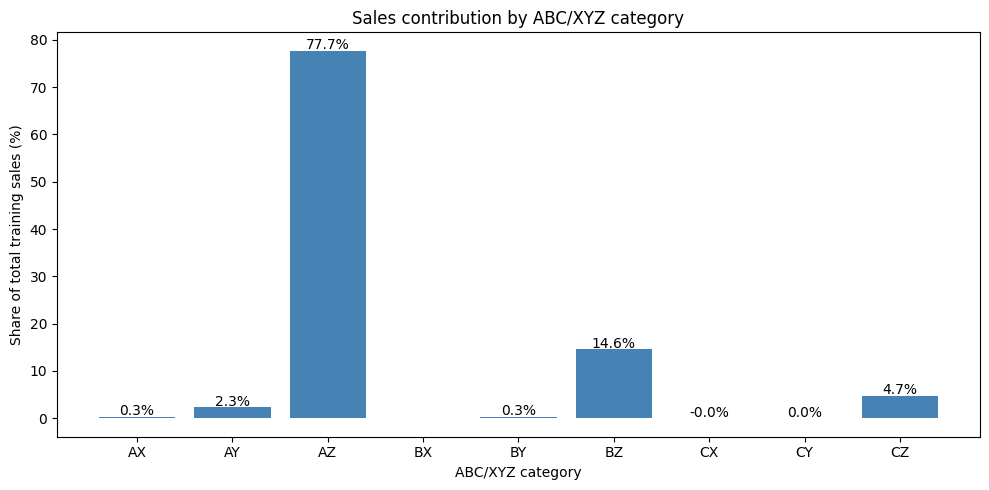

In [ ]:
plt.figure(figsize=(10,5))

bars = plt.bar(
    category_sales_summary["ABC_XYZ"],
    category_sales_summary["SalesSharePct"],
    color="steelblue"
)

plt.title("Sales contribution by ABC/XYZ category")
plt.xlabel("ABC/XYZ category")
plt.ylabel("Share of total training sales (%)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.3,
        f"{height:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

## Influence of zero-variance demand items

Items with a null standard deviation deserve a separate analysis because they correspond to quasi-constant demand profiles.
These items may have a stabilizing role in the portfolio and may also artificially improve some global indicators if they are mixed with highly erratic references.

The objective here is therefore to identify these items and quantify their contribution to total sales.

In [ ]:
# Identify items with zero monthly standard deviation in the XYZ table
zero_std_items = xyz.loc[xyz["StdMonthlyDemand"].fillna(0) == 0].copy()

# Merge business information including sales volume
zero_std_items = zero_std_items.merge(
    stock_base[
        ["Code article", "TrainingSalesVolume"]
    ],
    on="Code article",
    how="left"
)

zero_std_items["TrainingSalesVolume"] = zero_std_items["TrainingSalesVolume"].fillna(0)

(zero_std_items)

In [ ]:
# Quantify the weight of zero-variance items in total training sales
zero_std_sales = zero_std_items["TrainingSalesVolume"].sum()
all_sales = stock_base["TrainingSalesVolume"].sum()

zero_std_summary = pd.DataFrame({
    "Metric": [
        "Number of zero-variance items",
        "Total sales volume of zero-variance items",
        "Share of total training sales (%)"
    ],
    "Value": [
        zero_std_items["Code article"].nunique(),
        zero_std_sales,
        100 * zero_std_sales / all_sales if all_sales > 0 else np.nan
    ]
})

zero_std_summary

In [ ]:
ids = zero_std_items["Code article"].unique()

filtered_train = train_site1[
    train_site1["Code article"].isin(ids)
]

display(
    filtered_train[
        ["Code article", "Article annulé", "Date de commande", "Quantité commandée", "Quantité livrée"]
    ].head(50)
)

In [ ]:
# Visualize the sales contribution of zero-variance items versus the rest of the portfolio
sales_comparison = pd.DataFrame({
    "Group": ["Zero-variance items", "Other items"],
    "SalesVolume": [
        zero_std_sales,
        all_sales - zero_std_sales
    ]
})

plt.figure(figsize=(7, 4))
plt.bar(sales_comparison["Group"], sales_comparison["SalesVolume"])
plt.title("Influence of zero-variance demand items on total sales")
plt.ylabel("Training sales volume")
plt.tight_layout()
plt.show()

## Additional seasonality exploration with PACF

Autocorrelation was used as the primary exploratory tool for seasonality detection.
As a complement, partial autocorrelation can help determine whether the apparent dependence at a given lag remains significant once intermediate lags are controlled for.

PACF does not replace the previous approach, but it provides an additional diagnostic view of temporal structure.

In [ ]:
pacf_records = []
valid_lags = {3, 4, 6, 12}  # ← uniquement les lags métier

for article in monthly_train_pivot.columns:
    series = monthly_train_pivot[article].astype(float)

    n_obs = len(series)
    max_allowed_lag = min(12, max(1, n_obs // 2 - 1))

    if max_allowed_lag < 1:
        pacf_records.append({
            "Code article": article,
            "PACF_SelectedLag": np.nan,
            "PACF_SelectedValue": np.nan
        })
        continue

    try:
        pacf_values = pacf(series, nlags=max_allowed_lag, method="ywm")
        threshold = 1.96 / np.sqrt(n_obs)

        candidate_lags = []
        for lag in range(1, len(pacf_values)):
            value = pacf_values[lag]
            if lag in valid_lags and np.isfinite(value) and (value > threshold):  # ← filtre ici
                candidate_lags.append((lag, value))

        if len(candidate_lags) > 0:
            best_lag, best_value = max(candidate_lags, key=lambda x: x[1])
        else:
            best_lag, best_value = np.nan, np.nan

        pacf_records.append({
            "Code article": article,
            "PACF_SelectedLag": best_lag,
            "PACF_SelectedValue": best_value
        })

    except Exception:
        pacf_records.append({
            "Code article": article,
            "PACF_SelectedLag": np.nan,
            "PACF_SelectedValue": np.nan
        })

pacf_df = pd.DataFrame(pacf_records)
display_random_rows(pacf_df)

/usr/local/lib/python3.12/dist-packages/statsmodels/regression/linear_model.py:1490: ValueWarning: Matrix is singular. Using pinv.
  warnings.warn("Matrix is singular. Using pinv.", ValueWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/regression/linear_model.py:1490: ValueWarning: Matrix is singular. Using pinv.
  warnings.warn("Matrix is singular. Using pinv.", ValueWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/regression/linear_model.py:1490: ValueWarning: Matrix is singular. Using pinv.
  warnings.warn("Matrix is singular. Using pinv.", ValueWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/regression/linear_model.py:1490: ValueWarning: Matrix is singular. Using pinv.
  warnings.warn("Matrix is singular. Using pinv.", ValueWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/regression/linear_model.py:1490: ValueWarning: Matrix is singular. Using pinv.
  warnings.warn("Matrix is singular. Using pinv.", ValueWarning)
/usr/local/lib/pytho

,Code article,PACF_SelectedLag,PACF_SelectedValue
4504,212030,NaN,NaN
9630,2910044,NaN,NaN
684,1536,NaN,NaN
12706,5000108,NaN,NaN
5320,2219010,NaN,NaN
6828,2303900,NaN,NaN
11450,4111,NaN,NaN
10924,387,NaN,NaN


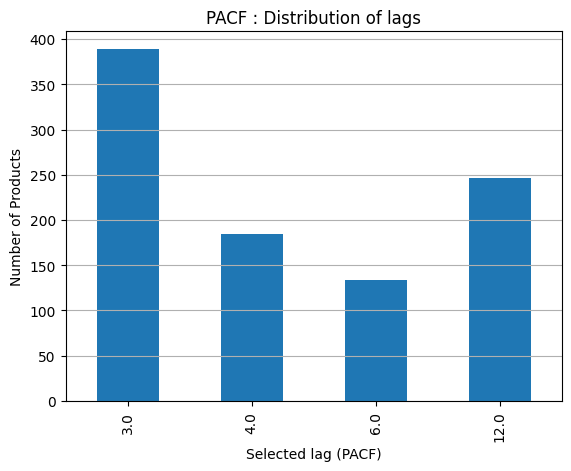

In [ ]:
# Nettoyage
valid_lags = pacf_df["PACF_SelectedLag"].dropna()

# Comptage
lag_counts = valid_lags.value_counts().sort_index()

# Plot
plt.figure()
lag_counts.plot(kind="bar")

plt.xlabel("Selected lag (PACF)")
plt.ylabel("Number of Products")
plt.title("PACF : Distribution of lags")

plt.grid(axis="y")
plt.show()

In [ ]:
# Compare ACF- and PACF-based diagnostics in a single table
seasonality_comparison = seasonality_df.merge(
    pacf_df,
    on="Code article",
    how="left"
)

display_random_rows(seasonality_comparison)

,Code article,SignificanceThreshold,ACF_3,ACF_4,ACF_6,ACF_12,SeasonalLag,MaxSignificantACF,PACF_SelectedLag,PACF_SelectedValue
8156,2347,0.322222,-0.027996,-0.028868,-0.030788,-0.038462,NaN,NaN,NaN,NaN
3250,2060015,0.322222,-0.009901,-0.010204,-0.347826,-0.023729,NaN,NaN,NaN,NaN
9761,29900,0.322222,0.227678,-0.076238,-0.108387,NaN,NaN,NaN,NaN,NaN
11154,40022401,0.322222,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4904,215600,0.322222,-0.030303,-0.031250,-0.033333,-0.041667,NaN,NaN,NaN,NaN
10623,34615,0.322222,-0.030303,-0.031250,-0.033333,-0.041667,NaN,NaN,NaN,NaN
4689,2134,0.322222,0.603113,0.526373,0.277752,0.582887,3.0,0.603113,NaN,NaN
5446,2220225,0.322222,0.891751,NaN,NaN,NaN,3.0,0.891751,3.0,0.398816


In [ ]:
from statsmodels.tsa.holtwinters import Holt, ExponentialSmoothing

# ============================================================
# MODEL FIT FUNCTION (PACF-based)
# ============================================================

def fit_exponential_smoothing_pacf(series, pacf_lag):

    series = pd.Series(series).astype(float)

    if series.std() == 0:
        return None, "constant"

    valid_lags = [3, 4, 6, 12]

    if pd.notna(pacf_lag) and int(pacf_lag) in valid_lags:

        seasonal_lag = int(pacf_lag)

        if len(series) < 2 * seasonal_lag:
            return None, "Holt_fallback"

        try:
            model = ExponentialSmoothing(
                series,
                trend="add",
                seasonal="add",
                seasonal_periods=seasonal_lag,
                initialization_method="estimated"
            ).fit(optimized=True)

            return model, f"HoltWinters({seasonal_lag})"

        except Exception:
            pass

    try:
        model = Holt(
            series,
            damped_trend=True,  # ← correction ici
            initialization_method="estimated"
        ).fit(optimized=True)

        return model, "Holt_damped"

    except Exception:
        return None, "error"


# ============================================================
# FORECAST LOOP
# ============================================================

forecast_records = []

if forecast_horizon > 0:

    for article in monthly_train_pivot.columns:

        train_series = monthly_train_pivot[article]

        if article in monthly_test_pivot.columns:
            test_series = monthly_test_pivot[article]
        else:
            test_series = pd.Series(index=monthly_test_pivot.index, data=0.0)

        pacf_match = pacf_df.loc[
            pacf_df["Code article"] == article, "PACF_SelectedLag"
        ]
        pacf_lag = pacf_match.iloc[0] if len(pacf_match) > 0 else np.nan

        model, model_name = fit_exponential_smoothing_pacf(train_series, pacf_lag)

        if model is None:
            fallback_value = train_series.iloc[-3:].median()  # ← correction ici
            pred = pd.Series(
                [fallback_value] * forecast_horizon,
                index=monthly_test_pivot.index
            )
        else:
            pred = pd.Series(
                model.forecast(forecast_horizon),
                index=monthly_test_pivot.index
            )

        pred = pred.clip(lower=0)

        for dt, actual, forecast_value in zip(
            monthly_test_pivot.index,
            test_series.values,
            pred.values
        ):
            forecast_records.append({
                "Code article": article,
                "Month": dt,
                "ActualDemand": float(actual),
                "ForecastDemand": float(forecast_value),
                "ModelUsed": model_name,
                "PACF_Lag": pacf_lag
            })

forecast_df = pd.DataFrame(forecast_records)

# ============================================================
# EVALUATION
# ============================================================

def safe_mape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan

    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


evaluation_rows = []

if len(forecast_df) > 0:

    for article, grp in forecast_df.groupby("Code article"):

        y_true = grp["ActualDemand"].values
        y_pred = grp["ForecastDemand"].values

        mae = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        mape = safe_mape(y_true, y_pred)

        evaluation_rows.append({
            "Code article": article,
            "ModelUsed": grp["ModelUsed"].iloc[0],
            "PACF_Lag": grp["PACF_Lag"].iloc[0],
            "MAE": mae,
            "RMSE": rmse,
            "MAPE": mape
        })

evaluation_df = pd.DataFrame(evaluation_rows)

display_random_rows(evaluation_df)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/holtwinters/model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/holtwinters/model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


,Code article,ModelUsed,PACF_Lag,MAE,RMSE,MAPE
8227,23708022,HoltWinters(3),3.0,0.675213,0.731601,22.222222
6457,2302239,Holt_damped,NaN,0.157193,0.157193,NaN
15218,DS504,Holt_damped,NaN,0.000000,0.000000,NaN
14736,DS1949,constant,NaN,0.000000,0.000000,NaN
15075,DS432264,Holt_damped,NaN,3.251449,3.272600,242.082565
5568,225,Holt_damped,NaN,0.293293,0.293293,NaN
4824,21497,Holt_damped,NaN,2.047716,2.240771,84.836834
14668,DS1489,Holt_damped,NaN,0.089138,0.089139,NaN


In [ ]:
# Nettoyer les colonnes dupliquées si elles existent déjà
cols_to_drop = [c for c in ["ABC", "XYZ", "ABC_XYZ", "ABC_x", "XYZ_x", "ABC_y", "XYZ_y"] if c in forecast_df.columns]
forecast_df = forecast_df.drop(columns=cols_to_drop)

# Ajout des classes ABC et XYZ
forecast_df = forecast_df.merge(
    stock_base_pacf[["Code article", "ABC", "XYZ"]],
    on="Code article",
    how="left"
)

forecast_df["ABC_XYZ"] = (
    forecast_df["ABC"].astype(str)
    + forecast_df["XYZ"].astype(str)
)

print(forecast_df["ABC_XYZ"].value_counts(dropna=False))

In [ ]:
last_month_pacf = forecast_df["Month"].max()
forecast_filtered_pacf = forecast_df[forecast_df["Month"] < last_month_pacf]

daily_demand_stats_pacf = (
    forecast_filtered_pacf.groupby("Code article")["ForecastDemand"]
    .agg(
        mu_d=lambda x: x.mean() / 22,
        sigma_d=lambda x: x.std() / 22
    )
    .reset_index()
)

stock_base_pacf = (
    abc_xyz
    .merge(seasonality_df[["Code article", "SeasonalLag"]], on="Code article", how="left")
    .merge(daily_demand_stats_pacf, on="Code article", how="left")
    .merge(lead_time_stats, on="Code article", how="left")
    .merge(evaluation_df[["Code article", "ModelUsed", "MAE", "RMSE", "MAPE"]], on="Code article", how="left")
)

stock_base_pacf["mu_l"] = stock_base_pacf["mu_l"].fillna(0.0)
stock_base_pacf["sigma_l"] = stock_base_pacf["sigma_l"].fillna(0.0)
stock_base_pacf["sigma_d"] = stock_base_pacf["sigma_d"].fillna(0.0)

stock_base_pacf["F1"] = stock_base_pacf["mu_d"] * stock_base_pacf["mu_l"]
stock_base_pacf["F2"] = stock_base_pacf["mu_d"] * stock_base_pacf["mu_l"] + z * stock_base_pacf["sigma_d"] * np.sqrt(stock_base_pacf["sigma_l"])
stock_base_pacf["F3"] = stock_base_pacf["mu_d"] * stock_base_pacf["mu_l"] + z * np.sqrt(
    stock_base_pacf["mu_l"] * (stock_base_pacf["sigma_d"] ** 2) + (stock_base_pacf["mu_d"] * stock_base_pacf["sigma_l"]) ** 2
)

for col in ["F1", "F2", "F3"]:
    stock_base_pacf[col] = stock_base_pacf[col].clip(lower=0)

display_random_rows(stock_base_pacf)

,Code article,ABC,XYZ,ABC_XYZ,SeasonalLag,mu_d,sigma_d,mu_l,sigma_l,LeadTimeObs,ModelUsed,MAE,RMSE,MAPE,F1,F2,F3
11554,41436,C,Z,CZ,12.0,0.423983,0.008717,10.812500,2.740820,32.0,Holt_damped,4.859156,5.311801,94.132967,4.584317,4.617942,7.292743
9997,2MP35OA,C,Z,CZ,6.0,0.002606,0.000075,6.600000,5.029911,5.0,Holt_damped,0.056817,0.056844,NaN,0.017200,0.017590,0.047745
4717,213629,C,Z,CZ,NaN,0.000000,0.000000,3.000000,0.000000,1.0,Holt_damped,0.000000,0.000000,NaN,0.000000,0.000000,0.000000
72,0941110,C,Z,CZ,NaN,0.000634,0.000042,0.000000,0.000000,NaN,Holt_damped,0.013651,0.013687,NaN,0.000000,0.000000,0.000000
11414,40897000,A,Z,AZ,NaN,4.505360,0.000292,8.557692,5.442799,52.0,Holt_damped,39.581351,49.364357,71.337326,38.555482,38.557069,95.691196
2950,2041803,C,Z,CZ,12.0,0.056902,0.058092,10.000000,3.807887,5.0,HoltWinters(12),1.117284,1.322227,124.691365,0.569023,0.833150,1.230906
2433,2020074,C,Z,CZ,NaN,0.258134,0.005008,44.000000,0.000000,1.0,Holt_damped,5.711953,5.713138,NaN,11.357883,11.357883,11.435286
9705,29573,B,Z,BZ,12.0,0.549777,0.001803,13.363636,9.790533,11.0,Holt_damped,9.939424,10.216525,397.696200,7.347017,7.360161,19.888502


In [ ]:
daily_demand_test_pacf = daily_demand_test_base.merge(
    stock_base_pacf[["Code article", "F1", "F2", "F3", "mu_l"]],
    on="Code article",
    how="left"
)
daily_demand_test_pacf["mu_l_int"] = daily_demand_test_pacf["mu_l"].fillna(0).round().astype(int)

coverage_rows_pacf = []

for article, df in daily_demand_test_pacf.groupby("Code article"):
    df = df.sort_values("Date").reset_index(drop=True)
    mu_l = max(df["mu_l_int"].iloc[0], 1)
    avg_demand_lt = df["DemandJour"].rolling(window=mu_l, min_periods=1).sum().mean()
    f1 = df["F1"].iloc[0]
    f2 = df["F2"].iloc[0]
    f3 = df["F3"].iloc[0]
    coverage_rows_pacf.append({
        "Code article": article,
        "ABC_XYZ": df["ABC_XYZ"].iloc[0],
        "AvgDemand_LT": avg_demand_lt,
        "F1": f1, "F2": f2, "F3": f3,
        "FillRate_F1": min(f1 / avg_demand_lt, 1.0) * 100 if avg_demand_lt > 0 else np.nan,
        "FillRate_F2": min(f2 / avg_demand_lt, 1.0) * 100 if avg_demand_lt > 0 else np.nan,
        "FillRate_F3": min(f3 / avg_demand_lt, 1.0) * 100 if avg_demand_lt > 0 else np.nan,
    })

coverage_df_pacf = pd.DataFrame(coverage_rows_pacf)
coverage_df_clean_pacf = coverage_df_pacf[coverage_df_pacf["F1"] > 0].copy()

coverage_summary_pacf = (
    coverage_df_clean_pacf.groupby("ABC_XYZ")
    .agg(
        FillRate_F1=("FillRate_F1", "mean"),
        FillRate_F2=("FillRate_F2", "mean"),
        FillRate_F3=("FillRate_F3", "mean"),
        NbArticles=("Code article", "nunique")
    )
    .reindex(abcxyz_order)
    .reset_index()
)

coverage_summary_pacf["FillRate_F1"] = coverage_summary_pacf["FillRate_F1"].round(2)
coverage_summary_pacf["FillRate_F2"] = coverage_summary_pacf["FillRate_F2"].round(2)
coverage_summary_pacf["FillRate_F3"] = coverage_summary_pacf["FillRate_F3"].round(2)

coverage_summary_pacf

,ABC_XYZ,FillRate_F1,FillRate_F2,FillRate_F3,NbArticles
0,AX,100.00,100.00,100.00,3.0
1,AY,99.49,99.51,100.00,22.0
2,AZ,95.05,95.26,98.99,616.0
3,BX,NaN,NaN,NaN,NaN
4,BY,98.55,98.57,100.00,27.0
5,BZ,91.59,91.91,97.11,1383.0
6,CX,100.00,100.00,100.00,1.0
7,CY,95.92,96.14,100.00,15.0
8,CZ,55.00,55.84,67.35,3910.0


In [ ]:
import os

output_dir = "/content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast_pacf"
os.makedirs(output_dir, exist_ok=True)

abcxyz_order = ["AX","AY","AZ","BX","BY","BZ","CX","CY","CZ"]

# Ensure ABC and XYZ classifications are present in forecast_df
# This logic is brought from cell D-nz4hiVo6ha to make this cell more robust.
# First, drop any existing ABC/XYZ related columns to avoid conflicts if cell D-nz4hiVo6ha was partially executed.
cols_to_drop = [c for c in ["ABC", "XYZ", "ABC_XYZ"] if c in forecast_df.columns]
forecast_df = forecast_df.drop(columns=cols_to_drop)

# Now merge with stock_base_pacf to get ABC and XYZ
# Ensure stock_base_pacf exists by running cell 7SjFkkmxndGC if it hasn't been executed yet.
if 'stock_base_pacf' in locals(): # Check if stock_base_pacf is defined
    forecast_df = forecast_df.merge(
        stock_base_pacf[["Code article", "ABC", "XYZ"]],
        on="Code article",
        how="left"
    )
    # Create the combined ABC_XYZ column
    forecast_df["ABC_XYZ"] = (
        forecast_df["ABC"].astype(str)
        + forecast_df["XYZ"].astype(str)
    )
else:
    print("Error: 'stock_base_pacf' is not defined. Please run cell 7SjFkkmxndGC first.")
    # If stock_base_pacf is not defined, we cannot proceed with ABC_XYZ creation.
    # We might need to handle this gracefully, e.g., by skipping export or setting ABC_XYZ to NaN/default.
    # For now, we will add a placeholder and let the loop continue, it might fail on df_cat.empty check.
    forecast_df["ABC"] = None
    forecast_df["XYZ"] = None
    forecast_df["ABC_XYZ"] = "NaNNaN" # Placeholder to prevent immediate KeyError in the loop

for cat in abcxyz_order:

    df_cat = forecast_df[forecast_df["ABC_XYZ"] == cat].copy()

    if df_cat.empty:
        print(f"Aucune donnée pour {cat}")
        continue

    df_cat = df_cat.sort_values(["Code article", "Month"])

    df_cat = df_cat[
        ["Code article", "Month", "ActualDemand", "ForecastDemand", "PACF_Lag"]  # ← ajout ici
    ]

    file_path = f"{output_dir}/forecast_PACF_{cat}.xlsx"
    df_cat.to_excel(file_path, index=False)

    print(f"Export OK : {file_path}")

print("Tous les exports PACF terminés 🚀")

Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast_pacf/forecast_PACF_AX.xlsx
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast_pacf/forecast_PACF_AY.xlsx
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast_pacf/forecast_PACF_AZ.xlsx
Aucune donnée pour BX
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast_pacf/forecast_PACF_BY.xlsx
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast_pacf/forecast_PACF_BZ.xlsx
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast_pacf/forecast_PACF_CX.xlsx
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast_pacf/forecast_PACF_CY.xlsx
Export OK : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast_pacf/forecast_PACF_CZ.xlsx
Tous les exports PACF terminés 🚀


In [ ]:
# ===============================
# Résumé des erreurs par classe ABC-XYZ
# ===============================

# Fusion des erreurs avec les classes
evaluation_with_classes = evaluation_df.merge(
    stock_base_pacf[["Code article", "ABC", "XYZ"]],
    on="Code article",
    how="left"
)

# Création de la classe combinée
evaluation_with_classes["ABC_XYZ"] = (
    evaluation_with_classes["ABC"].astype(str)
    + evaluation_with_classes["XYZ"].astype(str)
)

# Ordre logique des classes
abcxyz_order = ["AX","AY","AZ","BX","BY","BZ","CX","CY","CZ"]

# Agrégation des métriques
abcxyz_summary = (
    evaluation_with_classes
    .groupby("ABC_XYZ")
    .agg(
        NumberOfArticles=("Code article","nunique"),
        MeanMAE=("MAE","mean"),
        MeanMAPE=("MAPE","mean")
    )
    .reindex(abcxyz_order)
    .reset_index()
)

# Remplacer les NaN si certaines classes sont absentes
abcxyz_summary = abcxyz_summary.fillna(0)

# Affichage
abcxyz_summary

,ABC_XYZ,NumberOfArticles,MeanMAE,MeanMAPE
0,AX,3.0,44.014634,29.986449
1,AY,23.0,97.001531,330.936037
2,AZ,683.0,106.387692,112.858968
3,BX,0.0,0.000000,0.000000
4,BY,27.0,19.574970,58.067858
5,BZ,1600.0,14.556099,150.738535
6,CX,12.0,1.450615,90.211834
7,CY,16.0,8.174501,75.032082
8,CZ,11889.0,1.204770,101.895642


In [ ]:
# Exclure le dernier mois pour chaque article dans forecast_df
last_month_global = forecast_df["Month"].max()

evaluation_df_filtered = (
    forecast_df[forecast_df["Month"] < last_month_global]
    .groupby("Code article")
    .apply(lambda x: pd.Series({
        "MAE": mean_absolute_error(x["ActualDemand"], x["ForecastDemand"]),
        "RMSE": np.sqrt(mean_squared_error(x["ActualDemand"], x["ForecastDemand"])),
        "MAPE": safe_mape(x["ActualDemand"].values, x["ForecastDemand"].values),
        "ModelUsed": x["ModelUsed"].iloc[0],
        "PACF_Lag": x["PACF_Lag"].iloc[0]
    }), include_groups=False)
    .reset_index()
)

# Fusion avec classes ABC_XYZ
evaluation_with_classes = evaluation_df_filtered.merge(
    stock_base_pacf[["Code article", "ABC", "XYZ"]], # Corrected from stock_base to stock_base_pacf
    on="Code article",
    how="left"
)

evaluation_with_classes["ABC_XYZ"] = (
    evaluation_with_classes["ABC"].astype(str)
    + evaluation_with_classes["XYZ"].astype(str)
)

abcxyz_order = ["AX","AY","AZ","BX","BY","BZ","CX","CY","CZ"]

abcxyz_summary = (
    evaluation_with_classes
    .groupby("ABC_XYZ")
    .agg(
        NumberOfArticles=("Code article","nunique"),
        MeanMAE=("MAE","mean"),
        MeanMAPE=("MAPE","mean")
    )
    .reindex(abcxyz_order)
    .reset_index()
)

abcxyz_summary = abcxyz_summary.fillna(0)
abcxyz_summary

,ABC_XYZ,NumberOfArticles,MeanMAE,MeanMAPE
0,AX,3.0,30.034013,17.145813
1,AY,23.0,76.263225,314.751366
2,AZ,683.0,92.720371,83.426894
3,BX,0.0,0.000000,0.000000
4,BY,27.0,15.731497,46.198928
5,BZ,1600.0,13.716551,127.259687
6,CX,12.0,1.337624,87.947721
7,CY,16.0,7.148699,69.793276
8,CZ,11889.0,1.185665,98.312220


In [ ]:
last_month_pacf = forecast_df["Month"].max()
forecast_filtered_pacf = forecast_df[forecast_df["Month"] < last_month_pacf]

daily_demand_stats_pacf = (
    forecast_filtered_pacf.groupby("Code article")["ForecastDemand"]
    .agg(
        mu_d=lambda x: x.mean() / 22,
        sigma_d=lambda x: x.std() / 22
    )
    .reset_index()
)

stock_base_pacf = (
    abc_xyz
    .merge(seasonality_df[["Code article", "SeasonalLag"]], on="Code article", how="left")
    .merge(daily_demand_stats_pacf, on="Code article", how="left")
    .merge(lead_time_stats, on="Code article", how="left")
    .merge(evaluation_df[["Code article", "ModelUsed", "MAE", "RMSE", "MAPE"]], on="Code article", how="left")
)

stock_base_pacf["mu_l"] = stock_base_pacf["mu_l"].fillna(0.0)
stock_base_pacf["sigma_l"] = stock_base_pacf["sigma_l"].fillna(0.0)
stock_base_pacf["sigma_d"] = stock_base_pacf["sigma_d"].fillna(0.0)

stock_base_pacf["F1"] = stock_base_pacf["mu_d"] * stock_base_pacf["mu_l"]
stock_base_pacf["F2"] = stock_base_pacf["mu_d"] * stock_base_pacf["mu_l"] + z * stock_base_pacf["sigma_d"] * np.sqrt(stock_base_pacf["sigma_l"])
stock_base_pacf["F3"] = stock_base_pacf["mu_d"] * stock_base_pacf["mu_l"] + z * np.sqrt(
    stock_base_pacf["mu_l"] * (stock_base_pacf["sigma_d"] ** 2) + (stock_base_pacf["mu_d"] * stock_base_pacf["sigma_l"]) ** 2
)

for col in ["F1", "F2", "F3"]:
    stock_base_pacf[col] = stock_base_pacf[col].clip(lower=0)

display_random_rows(stock_base_pacf)

,Code article,ABC,XYZ,ABC_XYZ,SeasonalLag,mu_d,sigma_d,mu_l,sigma_l,LeadTimeObs,ModelUsed,MAE,RMSE,MAPE,F1,F2,F3
10422,3270,A,Z,AZ,NaN,1.536874,1.377231e-03,12.687500,5.816285,16.0,Holt_damped,12.036983,16.777956,188.943437,19.499090,19.506829,40.326723
12360,46121,C,Z,CZ,NaN,0.009664,5.074545e-04,9.750000,5.418223,8.0,Holt_damped,0.834507,1.092024,85.473870,0.094229,0.096981,0.216293
5381,2220138,C,Z,CZ,NaN,0.013714,6.460377e-05,7.000000,4.062019,5.0,Holt_damped,0.868174,1.534778,92.455132,0.095997,0.096301,0.225793
7641,2308892,C,Z,CZ,NaN,0.002166,1.866803e-05,0.000000,0.000000,NaN,Holt_damped,0.047776,0.047778,NaN,0.000000,0.000000,0.000000
8895,251101,B,NaN,B?,12.0,2.034182,7.039149e-02,11.101266,4.445092,79.0,Holt_damped,19.061545,21.855311,79.585998,22.581996,22.927789,43.657237
14201,795,C,Z,CZ,12.0,0.000000,0.000000e+00,17.000000,7.000000,3.0,Holt_damped,0.000000,0.000000,NaN,0.000000,0.000000,0.000000
5229,220024,C,Z,CZ,NaN,0.009690,4.916552e-07,4.250000,1.669046,8.0,Holt_damped,1.666667,2.309720,92.893672,0.041184,0.041186,0.078869
11874,43373,B,Z,BZ,NaN,0.961526,4.781256e-04,8.414286,4.651610,70.0,Holt_damped,10.822994,12.143031,185.792218,8.090556,8.092959,18.511818


In [ ]:
daily_demand_test_pacf = daily_demand_test_base.merge(
    stock_base_pacf[["Code article", "F1", "F2", "F3", "mu_l"]],
    on="Code article",
    how="left"
)
daily_demand_test_pacf["mu_l_int"] = daily_demand_test_pacf["mu_l"].fillna(0).round().astype(int)

coverage_rows_pacf = []

for article, df in daily_demand_test_pacf.groupby("Code article"):
    df = df.sort_values("Date").reset_index(drop=True)
    mu_l = max(df["mu_l_int"].iloc[0], 1)
    avg_demand_lt = df["DemandJour"].rolling(window=mu_l, min_periods=1).sum().mean()
    f1 = df["F1"].iloc[0]
    f2 = df["F2"].iloc[0]
    f3 = df["F3"].iloc[0]
    coverage_rows_pacf.append({
        "Code article": article,
        "ABC_XYZ": df["ABC_XYZ"].iloc[0],
        "AvgDemand_LT": avg_demand_lt,
        "F1": f1, "F2": f2, "F3": f3,
        "FillRate_F1": min(f1 / avg_demand_lt, 1.0) * 100 if avg_demand_lt > 0 else np.nan,
        "FillRate_F2": min(f2 / avg_demand_lt, 1.0) * 100 if avg_demand_lt > 0 else np.nan,
        "FillRate_F3": min(f3 / avg_demand_lt, 1.0) * 100 if avg_demand_lt > 0 else np.nan,
    })

coverage_df_pacf = pd.DataFrame(coverage_rows_pacf)
coverage_df_clean_pacf = coverage_df_pacf[coverage_df_pacf["F1"] > 0].copy()

coverage_summary_pacf = (
    coverage_df_clean_pacf.groupby("ABC_XYZ")
    .agg(
        FillRate_F1=("FillRate_F1", "mean"),
        FillRate_F2=("FillRate_F2", "mean"),
        FillRate_F3=("FillRate_F3", "mean"),
        NbArticles=("Code article", "nunique")
    )
    .reindex(abcxyz_order)
    .reset_index()
)

coverage_summary_pacf["FillRate_F1"] = coverage_summary_pacf["FillRate_F1"].round(2)
coverage_summary_pacf["FillRate_F2"] = coverage_summary_pacf["FillRate_F2"].round(2)
coverage_summary_pacf["FillRate_F3"] = coverage_summary_pacf["FillRate_F3"].round(2)

coverage_summary_pacf

,ABC_XYZ,FillRate_F1,FillRate_F2,FillRate_F3,NbArticles
0,AX,100.00,100.00,100.00,3.0
1,AY,99.49,99.51,100.00,22.0
2,AZ,95.05,95.26,98.99,616.0
3,BX,NaN,NaN,NaN,NaN
4,BY,98.55,98.57,100.00,27.0
5,BZ,91.59,91.91,97.11,1383.0
6,CX,100.00,100.00,100.00,1.0
7,CY,95.92,96.14,100.00,15.0
8,CZ,55.00,55.84,67.35,3910.0


In [ ]:
import os

output_dir_pacf = "/content/drive/MyDrive/Colab Notebooks/dataPR/exports_stock_mini_pacf"
os.makedirs(output_dir_pacf, exist_ok=True)

for cat in abcxyz_order:
    df_cat = coverage_df_clean_pacf[coverage_df_clean_pacf["ABC_XYZ"] == cat].copy()
    if df_cat.empty:
        print(f"Aucune donnée PACF pour {cat}")
        continue
    df_cat = df_cat.sort_values("Code article")
    df_cat = df_cat[["Code article", "F1", "F2", "F3", "AvgDemand_LT", "FillRate_F1", "FillRate_F2", "FillRate_F3"]]
    df_cat.to_excel(f"{output_dir_pacf}/stock_mini_PACF_{cat}.xlsx", index=False)
    print(f"Export OK : stock_mini_PACF_{cat}.xlsx")

print("Tous les exports stock minimum PACF terminés 🚀")



Export OK : stock_mini_PACF_AX.xlsx
Export OK : stock_mini_PACF_AY.xlsx
Export OK : stock_mini_PACF_AZ.xlsx
Aucune donnée PACF pour BX
Export OK : stock_mini_PACF_BY.xlsx
Export OK : stock_mini_PACF_BZ.xlsx
Export OK : stock_mini_PACF_CX.xlsx
Export OK : stock_mini_PACF_CY.xlsx
Export OK : stock_mini_PACF_CZ.xlsx
Tous les exports stock minimum PACF terminés 🚀


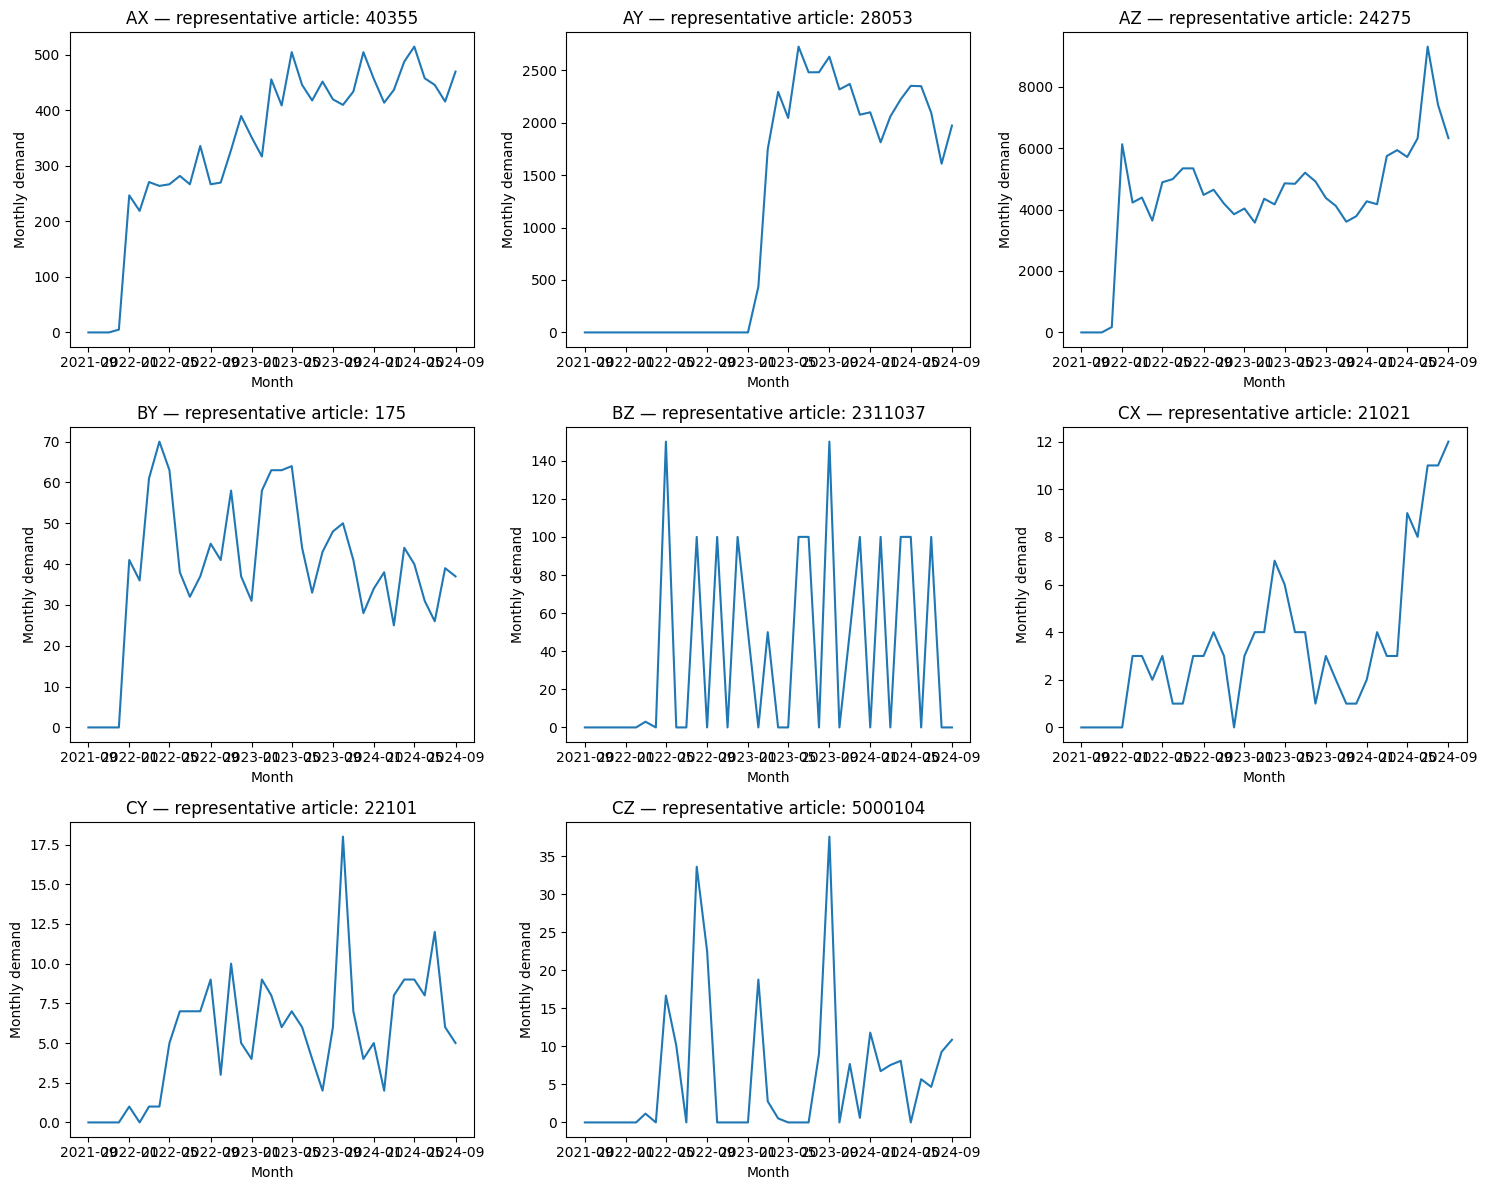

In [ ]:
# Plot one representative article per ABC/XYZ category when possible
representative_items = []

for category in abcxyz_order:
    subset = stock_base.loc[stock_base["ABC_XYZ"] == category].copy()

    if len(subset) == 0:
        continue

    # Select the top-selling item within the category as a representative example
    representative_article = subset.sort_values("TrainingSalesVolume", ascending=False)["Code article"].iloc[0]
    representative_items.append((category, representative_article))

n_plots = len(representative_items)
n_cols = 3
n_rows = int(np.ceil(n_plots / n_cols)) if n_plots > 0 else 1

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows), sharex=False)
axes = np.array(axes).reshape(-1)

for ax, (category, article) in zip(axes, representative_items):
    series = monthly_train_pivot[article]
    ax.plot(series.index, series.values)
    ax.set_title(f"{category} — representative article: {article}")
    ax.set_xlabel("Month")
    ax.set_ylabel("Monthly demand")

# Hide unused axes
for ax in axes[len(representative_items):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

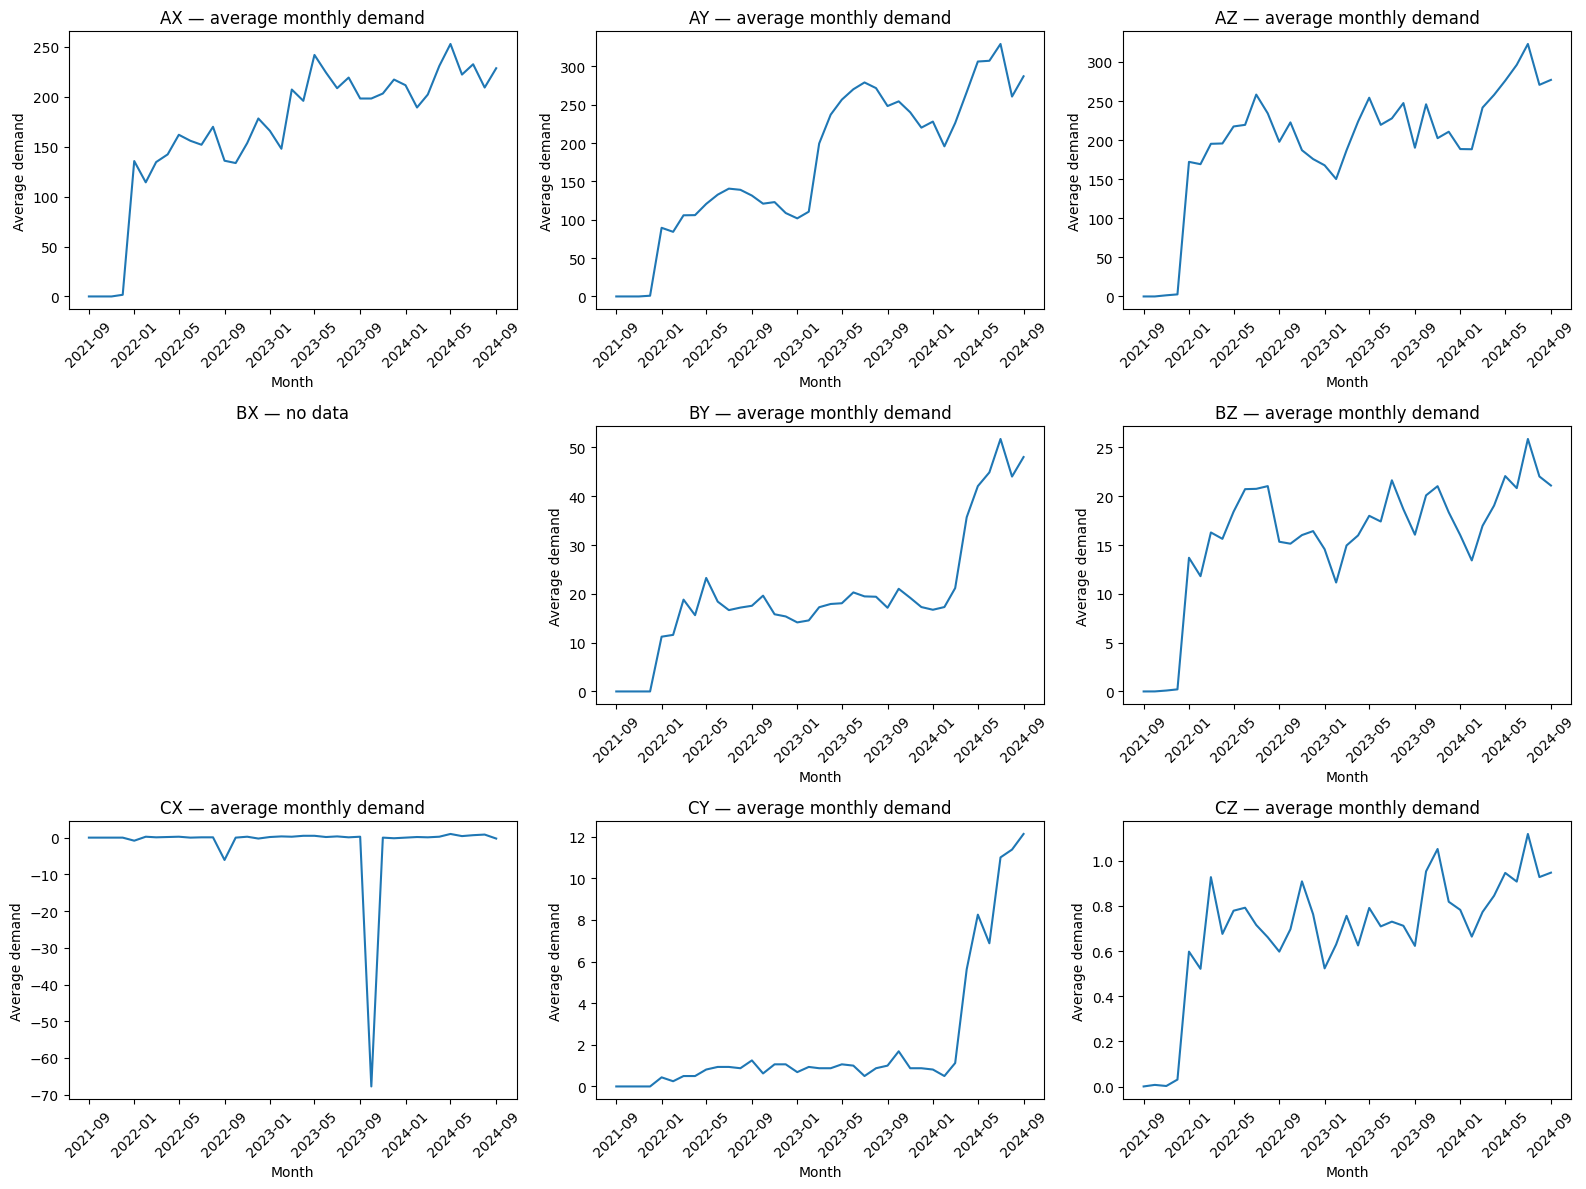

In [ ]:
# Compute the mean monthly demand profile for each ABC/XYZ category
monthly_long_with_category = monthly_train_long.merge(
    stock_base[["Code article", "ABC_XYZ"]],
    on="Code article",
    how="left"
)

# Ensure that the month column is interpreted as a datetime
monthly_long_with_category["Month"] = pd.to_datetime(monthly_long_with_category["Month"])

category_monthly_profile = (
    monthly_long_with_category.groupby(["Month", "ABC_XYZ"])["MonthlyDemand"]
    .mean()
    .reset_index()
)

# Plot average monthly demand by category
n_cols = 3
n_rows = 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 12), sharex=False)
axes = axes.flatten()

for ax, category in zip(axes, abcxyz_order):
    subset = category_monthly_profile.loc[category_monthly_profile["ABC_XYZ"] == category]

    if len(subset) > 0:
        ax.plot(subset["Month"], subset["MonthlyDemand"])
        ax.set_title(f"{category} — average monthly demand")
        ax.set_xlabel("Month")
        ax.set_ylabel("Average demand")
        ax.tick_params(axis="x", rotation=45)
    else:
        ax.set_title(f"{category} — no data")
        ax.axis("off")

plt.tight_layout()
plt.show()

# Extraction par catégorie

On extrait les fichier par catégorie AX/AY...CZ avec la liste des ventes pour ces catégories.

In [ ]:
# ============================================================
# Export files for combined ABC/XYZ categories:
# AX, AY, AZ, BX, BY, BZ, CX, CY, CZ
# ============================================================
from pathlib import Path
import zipfile

# Working copy of the transactional dataset
site1_export_base = site1_work.copy()

# Recover ABC and XYZ classifications
abc_map = abc[["Code article", "ABC"]].drop_duplicates(subset=["Code article"]).copy()
xyz_map = xyz[["Code article", "XYZ"]].drop_duplicates(subset=["Code article"]).copy()

# Merge classifications
site1_export_base = site1_export_base.merge(abc_map, on="Code article", how="left")
site1_export_base = site1_export_base.merge(xyz_map, on="Code article", how="left")

# Create combined category
site1_export_base["ABC_XYZ"] = site1_export_base["ABC"].astype(str) + site1_export_base["XYZ"].astype(str)

# Export folder
export_dir = Path("exports_AX_AY_AZ_categories")
export_dir.mkdir(exist_ok=True)

# List of categories
abcxyz_categories = ["AX","AY","AZ","BX","BY","BZ","CX","CY","CZ"]

# Export one CSV per category
for cat in abcxyz_categories:

    subset = site1_export_base.loc[site1_export_base["ABC_XYZ"] == cat].copy()

    if len(subset) == 0:
        continue

    subset.to_csv(export_dir / f"site1_category_{cat}.csv", index=False)

# ------------------------------------------------------------
# Create ZIP file for download
# ------------------------------------------------------------
zip_path = "exports_AX_AY_AZ_categories.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_path in export_dir.glob("*.csv"):
        zipf.write(file_path, arcname=file_path.name)

print("Export completed.")
print(f"Folder: {export_dir.resolve()}")
print(f"ZIP file: {Path(zip_path).resolve()}")

# Display random rows for verification
display_random_rows(site1_export_base)
site1_export_base["ABC_XYZ"].value_counts()

from google.colab import files
files.download("exports_AX_AY_AZ_categories.zip")

Export completed.
Folder: /content/exports_AX_AY_AZ_categories
ZIP file: /content/exports_AX_AY_AZ_categories.zip


,Code fournisseur,Fournisseur annulé,Code article,Libellé article,Article annulé,Durée de vie Hélios (en jours),Durée de vie calculée (en jours),Catégorie article,Intitulé famille tarif article,Intitulé sous-famille tarif article,...,Date de livraison,CA,Quantité commandée,Quantité livrée,Quantité de manquants,OrderMonth,OrderMonthStart,ABC,XYZ,ABC_XYZ
725,57,Fournisseur non annulé,1092,LA_6537,Article non annulé,0.0,NaN,C_7,F_111,SF_51,...,2025-03-01,53.10,1.0,1.0,0.0,2025-02,2025-02-01,B,Z,BZ
649688,1456,Fournisseur non annulé,41899,LA_173,Article non annulé,365.0,1025.0,C_12,F_65,SF_173,...,2024-12-23,62.67,3.0,3.0,0.0,2024-12,2024-12-01,A,Z,AZ
1651532,855,Fournisseur non annulé,2654,LA_8137,Article non annulé,0.0,NaN,C_12,F_40,SF_33,...,2023-07-21,9.55,1.0,1.0,0.0,2023-07,2023-07-01,A,Z,AZ
458974,251,Fournisseur non annulé,20729,LA_8393,Article non annulé,0.0,NaN,C_12,F_41,SF_162,...,2024-12-27,36.53,1.0,1.0,0.0,2024-12,2024-12-01,A,Z,AZ
359071,1631,Fournisseur non annulé,40014,LA_3997,Article non annulé,60.0,214.0,C_12,F_75,SF_560,...,2022-02-22,16.58,1.0,1.0,0.0,2022-02,2022-02-01,B,Z,BZ
1925915,20005,Fournisseur non annulé,29044,LA_5287,Article non annulé,0.0,NaN,C_11,F_126,SF_20,...,2023-09-05,31.84,1.0,1.0,0.0,2023-09,2023-09-01,C,Z,CZ
1066117,1499,Fournisseur non annulé,29625,LA_3471,Article non annulé,365.0,889.0,C_13,F_5,SF_202,...,2024-05-14,40.00,1.0,1.0,0.0,2024-05,2024-05-01,B,Z,BZ
211531,1102,Fournisseur non annulé,6204,LA_8628,Article non annulé,0.0,NaN,C_7,F_111,SF_438,...,2022-01-12,4.36,1.0,1.0,0.0,2022-01,2022-01-01,C,Z,CZ


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

On extrait les fichier par catégorie AX/AY...CZ avec la liste des produits pour ces catégories.

In [ ]:
# ============================================================
# Export product lists for combined ABC/XYZ categories:
# AX, AY, AZ, BX, BY, BZ, CX, CY, CZ
# ============================================================

from pathlib import Path
import zipfile
import pandas as pd

# Build the ABC and XYZ mappings
abc_map = abc[["Code article", "ABC"]].drop_duplicates(subset=["Code article"]).copy()
xyz_map = xyz[["Code article", "XYZ"]].drop_duplicates(subset=["Code article"]).copy()

# Merge ABC and XYZ at article level
product_category_table = abc_map.merge(
    xyz_map,
    on="Code article",
    how="outer"
)

# Create the combined category label
product_category_table["ABC_XYZ"] = (
    product_category_table["ABC"].astype(str) + product_category_table["XYZ"].astype(str)
)

# Recover one descriptive row per product from the source dataset
candidate_description_cols = [
    "Code article",
    "Libellé article",
    "Catégorie article",
    "Intitulé famille tarif article",
    "Intitulé sous-famille tarif article",
    "Numéro d'entrepôt"
]

available_description_cols = [c for c in candidate_description_cols if c in site1_work.columns]

product_descriptions = (
    site1_work[available_description_cols]
    .drop_duplicates(subset=["Code article"])
    .copy()
)

# Merge descriptive information into the product-level category table
product_category_table = product_category_table.merge(
    product_descriptions,
    on="Code article",
    how="left"
)

# Reorder columns if the descriptive columns exist
ordered_cols = ["Code article"]
for col in [
    "Libellé article",
    "Catégorie article",
    "Intitulé famille tarif article",
    "Intitulé sous-famille tarif article",
    "Numéro d'entrepôt",
    "ABC",
    "XYZ",
    "ABC_XYZ"
]:
    if col in product_category_table.columns and col not in ordered_cols:
        ordered_cols.append(col)

product_category_table = product_category_table[ordered_cols]

# Create export folder
export_dir = Path("exports_product_lists_by_ABCXYZ")
export_dir.mkdir(exist_ok=True)

# Standard category order
abcxyz_categories = ["AX", "AY", "AZ", "BX", "BY", "BZ", "CX", "CY", "CZ"]

# Export one product-list CSV per category
for cat in abcxyz_categories:
    subset = product_category_table.loc[product_category_table["ABC_XYZ"] == cat].copy()

    if len(subset) == 0:
        continue

    subset = subset.sort_values("Code article").reset_index(drop=True)

    subset.to_csv(export_dir / f"product_list_{cat}.csv", index=False)

# Create one ZIP archive containing all product-list files
zip_path = "exports_product_lists_by_ABCXYZ.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_path in export_dir.glob("*.csv"):
        zipf.write(file_path, arcname=file_path.name)

print("Product-list export completed.")
print(f"Folder: {export_dir.resolve()}")
print(f"ZIP file: {Path(zip_path).resolve()}")

# Display a few random products for verification
display_random_rows(product_category_table)

from google.colab import files
files.download("exports_product_lists_by_ABCXYZ.zip")

Product-list export completed.
Folder: /content/exports_product_lists_by_ABCXYZ
ZIP file: /content/exports_product_lists_by_ABCXYZ.zip


,Code article,Libellé article,Catégorie article,Intitulé famille tarif article,Intitulé sous-famille tarif article,Numéro d'entrepôt,ABC,XYZ,ABC_XYZ
1647,2002935,LA_10139,C_11,F_126,SF_20,1,C,Z,CZ
5053,217886,LA_14276,C_11,F_126,SF_20,1,C,Z,CZ
5560,22450,LA_9326,C_7,F_107,SF_421,1,C,Z,CZ
12709,5000112,LA_3061,C_13,F_14,SF_315,1,C,Z,CZ
1687,2003106,LA_12086,C_11,F_126,SF_20,1,C,Z,CZ
15055,DS42863,LA_2494,C_6,F_127,SF_742,1,C,Z,CZ
13708,6685,LA_1741,C_13,F_9,SF_189,1,B,Z,BZ
6649,2302980,LA_11984,C_11,F_126,SF_20,1,C,Z,CZ


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import os

# Dossiers des exports existants
dir_acf = "/content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast"
dir_pacf = "/content/drive/MyDrive/Colab Notebooks/dataPR/exports_forecast_pacf"

abcxyz_order = ["AX", "AY", "AZ", "BX", "BY", "BZ", "CX", "CY", "CZ"]

acf_dfs = []
pacf_dfs = []

for cat in abcxyz_order:
    acf_path = f"{dir_acf}/forecast_{cat}.xlsx"
    pacf_path = f"{dir_pacf}/forecast_PACF_{cat}.xlsx"

    if os.path.exists(acf_path):
        df = pd.read_excel(acf_path)
        df["ABC_XYZ"] = cat
        acf_dfs.append(df)

    if os.path.exists(pacf_path):
        df = pd.read_excel(pacf_path)
        df["ABC_XYZ"] = cat
        pacf_dfs.append(df)

acf_all = pd.concat(acf_dfs, ignore_index=True)
pacf_all = pd.concat(pacf_dfs, ignore_index=True)

# Jointure
comparison_df = acf_all.merge(
    pacf_all[["Code article", "Month", "ForecastDemand", "PACF_Lag"]],
    on=["Code article", "Month"],
    how="inner",
    suffixes=("_ACF", "_PACF")
)

comparison_df = comparison_df[[
    "Code article", "Month", "ABC_XYZ",
    "ActualDemand",
    "ForecastDemand_ACF", "SeasonalLag",
    "ForecastDemand_PACF", "PACF_Lag"
]].sort_values(["Code article", "Month"])

print(comparison_df.shape)
print(comparison_df.head())

(85518, 8)
     Code article      Month ABC_XYZ  ActualDemand  ForecastDemand_ACF  \
4284          175 2024-10-01      BY          36.0           36.981264   
4285          175 2024-11-01      BY          43.0           37.001685   
4286          175 2024-12-01      BY          34.0           37.019021   
4287          175 2025-01-01      BY          40.0           37.033737   
4288          175 2025-02-01      BY          43.0           37.046229   

      SeasonalLag  ForecastDemand_PACF  PACF_Lag  
4284          NaN            36.981264       NaN  
4285          NaN            37.001685       NaN  
4286          NaN            37.019021       NaN  
4287          NaN            37.033737       NaN  
4288          NaN            37.046229       NaN  


In [ ]:
for cat in abcxyz_order:
    df_cat = comparison_df[comparison_df["ABC_XYZ"] == cat]
    if df_cat.empty:
        continue
    output_path = f"/content/drive/MyDrive/Colab Notebooks/dataPR/exports_comparison/comparison_{cat}.xlsx"
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    df_cat.to_excel(output_path, index=False)
    print(f"Exporté : {output_path}")

Exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_comparison/comparison_AX.xlsx
Exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_comparison/comparison_AY.xlsx
Exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_comparison/comparison_AZ.xlsx
Exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_comparison/comparison_BY.xlsx
Exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_comparison/comparison_BZ.xlsx
Exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_comparison/comparison_CX.xlsx
Exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_comparison/comparison_CY.xlsx
Exporté : /content/drive/MyDrive/Colab Notebooks/dataPR/exports_comparison/comparison_CZ.xlsx
